# 04 · Market value and the recruitment back-test

The project's question: using only what was known at the end of the 2015/16 season, which players
would a data-driven scouting system have recommended, and how did their careers go? The season
is closed, so every recommendation can be checked against what happened next.

1. **What the market paid for.** How much of a player's market value at the end of the season
   the season's numbers explain (age, minutes, league, the team, the profile), and which players
   were valued below what their numbers fetched elsewhere.
2. **What happened next.** How each player's value and career went after the season, scored
   against players of the same age, before any prediction is checked against it.
3. **The back-test.** Whether the players valued furthest below their numbers outgrew players of
   their age, against simple rules a club could have used instead.
4. **Shortlists.** What a club with a budget would have shortlisted on 30 June 2016, and what
   became of those players.

**Players:** the 1,335 outfield players with a profile (`02_player_profiles.ipynb`, with the
possession-value numbers of `03_possession_value.ipynb`, section 4). **What a club could see:**
the 2015/16 season and each player's Transfermarkt value on 30 June 2016, the market view
(`backtest` in the config; `01_data_exploration.ipynb`, section 4). Values set after that date
are outcomes: they never enter a model of the market view.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups) and
Transfermarkt via [dcaribou/transfermarkt-datasets](https://github.com/dcaribou/transfermarkt-datasets)
(valuations, appearances). Only aggregated results are shown, as StatsBomb's licence requires. Tables are
built by `make model`; see `docs/DATA_DICTIONARY.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor

from football_scouting.analysis.backtest import lexicographic, pick_means, pick_weights
from football_scouting.analysis.market import (
    market_players,
    out_of_fold,
    partial,
    profile_matrix,
    team_bootstrap,
    team_strength,
    value_model,
)
from football_scouting.analysis.outcomes import (
    LEVELS,
    club_ids,
    club_leagues,
    player_outcomes,
    season_minutes,
)
from football_scouting.analysis.profiles import LABELS
from football_scouting.analysis.values import pool_valuations, value_at
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import GREY, credit, position_colors, save, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()

OUTFIELD = list(cfg.profiles)
GROUP_NAMES = {g.code: g.name for g in cfg.comparison_groups}
COLORS = position_colors(cfg)
GROUP_COLORS = {g: COLORS["W" if g == "AMW" else g] for g in OUTFIELD}
LEAGUES = [c.name for c in cfg.statsbomb.competitions if c.scouting_pool]

## 1. What the market paid for

Transfermarkt's value on 30 June 2016 is the market's view a club could see when the season
ended. It is modelled from the season: the player's age, minutes and league, the strength of
their team, and the twelve statistics of their group's profile (shrunk, standardised within
the group). Values run from €0.1M to €120M and move in proportion, so they are modelled on the
log scale, and the model's misses read as ratios.

One model per comparison group: a ridge regression, with age through a curve (values rise into
the mid-twenties and fall after thirty) and the rest as straight lines (`analysis.market`). The
columns are added in steps, to see what each adds:

- **context**: age, minutes, league;
- **team**: the team's goal difference per match in its league (points per match tested too);
- **profile**: the twelve statistics.

Every model is judged on players it was not fitted on: ten folds that keep a team's players
together (a teammate shares the team's status, and the model would learn it from them), over 20
random splits of the teams. A team is the pool team the player played most for; for players who
moved in January, the team's strength is weighted by their minutes with each.

### 1.1 The players and their values

In [2]:
players = market_players(con, cfg).set_index("player_id")
players["log_value"] = np.log(players.value)
for league in LEAGUES[1:]:
    players[league] = (players.league == league).astype(float)
season_end = pd.Timestamp(
    con.sql("SELECT max(match_date) FROM matches WHERE scouting_pool").fetchone()[0]
)
players["after_season"] = players.value_date > season_end
values = con.sql("SELECT * FROM profile_values").df()
profile = {g: profile_matrix(values, g, cfg.profiles[g]) for g in OUTFIELD}


def by_group(d):
    return d.reindex(OUTFIELD).rename(index=GROUP_NAMES).rename_axis(index=None)


in_millions = players.value / 1e6
display(
    by_group(
        pd.DataFrame(
            {
                "Players": players.groupby("comparison_group").size(),
                "Median value (€M)": in_millions.groupby(players.comparison_group).median(),
                "25th percentile": in_millions.groupby(players.comparison_group).quantile(0.25),
                "75th percentile": in_millions.groupby(players.comparison_group).quantile(0.75),
                "Highest": in_millions.groupby(players.comparison_group).max(),
                "Valued after the season": players.groupby("comparison_group").after_season.mean(),
            }
        )
    )
    .style.format("{:.1f}")
    .format("{:,.0f}", subset="Players")
    .format("{:.0%}", subset="Valued after the season")
    .set_caption("Transfermarkt values on 30 June 2016")
)
strength = team_strength(con).set_index("team_id").goal_difference
fresh = players.value_date[players.after_season].value_counts()
print(
    f"{len(players):,} players, all valued on 30 June 2016. {players.after_season.sum()} valued "
    f"after the last matchday ({season_end.day} {season_end:%B %Y}), {fresh.iloc[0]} of them on "
    f"{fresh.index[0].day} {fresh.index[0]:%B}; the others' values a median "
    f"{players.value_age_days[~players.after_season].median():.0f} days old. "
    f"{len(strength)} teams, goal difference per match from {strength.min():+.2f} to "
    f"{strength.max():+.2f}."
)

,Players,Median value (€M),25th percentile,75th percentile,Highest,Valued after the season
Centre-backs,265,2.5,1.5,6.0,40.0,12%
Full-backs,267,2.5,1.3,6.0,35.0,11%
Central midfielders,321,3.5,1.5,8.0,70.0,14%
Attacking midfielders and wingers,305,4.0,2.0,12.0,120.0,12%
Centre-forwards,177,4.0,2.0,10.0,90.0,13%


1,335 players, all valued on 30 June 2016. 166 valued after the last matchday (17 May 2016), 164 of them on 1 June; the others' values a median 142 days old. 80 teams, goal difference per match from -1.43 to +2.19.


**Most values were set in winter.** One player in eight was valued after the last matchday,
almost all of them in the Euro 2016 squads' revaluation of 1 June. The others carry a value a
median 142 days old, from the winter revaluations (January and February), before the second
half of the season. Attacking midfielders, wingers and centre-forwards are valued highest
(median €4M, against €2.5M for full-backs and centre-backs), and every group spans more than two
orders of magnitude, from €0.1M up to €35M to €120M.

### 1.2 How much the season explains

Share of the variation in log value explained out of sample (R²), by step. Boosted trees on
every column check whether curves or interactions the ridge regression cannot draw would add
anything.

In [3]:
CONTEXT = ["age", "minutes", *LEAGUES[1:]]
TEAM = "team_goal_difference"
FULL = "+ team + profile"


def steps(g):
    stats = list(cfg.profiles[g])
    return {
        "Context": CONTEXT,
        "+ team (points)": [*CONTEXT, "team_points"],
        "+ team": [*CONTEXT, TEAM],
        FULL: [*CONTEXT, TEAM, *stats],
        "Context + profile": [*CONTEXT, *stats],
    }


def trees():
    return HistGradientBoostingRegressor(
        max_iter=600, learning_rate=0.02, max_depth=2, min_samples_leaf=20, random_state=0
    )


design = {
    g: players.loc[profile[g].index, [*CONTEXT, "team_points", TEAM]].join(profile[g])
    for g in OUTFIELD
}
explained, predicted = {}, {}
for g in OUTFIELD:
    X, y, teams = (
        design[g],
        players.log_value.loc[design[g].index],
        players.team_id.loc[design[g].index],
    )
    for name, columns in steps(g).items():
        r2, pred = out_of_fold(lambda c=columns: value_model(c), X[columns], y, teams)
        explained[g, name] = r2.mean()
        predicted[g, name] = pd.Series(pred, X.index)
    r2, _ = out_of_fold(trees, X[steps(g)[FULL]], y, teams, repeats=5)
    explained[g, "Boosted trees"] = r2.mean()
explained = pd.Series(explained).unstack()[[*steps("CB"), "Boosted trees"]]
display(
    by_group(explained)
    .style.format("{:.2f}")
    .set_caption("Log value on 30 June 2016 explained out of sample (R², teams held out)")
)
print(
    "The profile adds "
    + ", ".join(f"{explained.loc[g, FULL] - explained.loc[g, '+ team']:+.3f}" for g in OUTFIELD)
    + " to context and team; the team adds "
    + ", ".join(
        f"{explained.loc[g, FULL] - explained.loc[g, 'Context + profile']:+.3f}" for g in OUTFIELD
    )
    + " to context and profile ("
    + ", ".join(OUTFIELD)
    + ")."
)

,Context,+ team (points),+ team,+ team + profile,Context + profile,Boosted trees
Centre-backs,0.41,0.70,0.73,0.73,0.53,0.62
Full-backs,0.29,0.60,0.62,0.64,0.43,0.57
Central midfielders,0.30,0.64,0.68,0.68,0.47,0.60
Attacking midfielders and wingers,0.33,0.62,0.65,0.68,0.58,0.61
Centre-forwards,0.43,0.69,0.72,0.74,0.60,0.64


The profile adds -0.001, +0.018, +0.004, +0.027, +0.022 to context and team; the team adds +0.200, +0.205, +0.209, +0.100, +0.141 to context and profile (CB, FB, CM, AMW, CF).


**The team explains more of a player's value than the player's own numbers.** Age, minutes and
league explain 29% to 43% of the variation in log value. The team's strength takes it to 62% to
73%; goal difference per match, which also counts the margin of each result, does slightly
better than points per match (0.60 to 0.70) and is the measure kept. On top of context and team,
the twelve profile statistics add at most 0.03 (nothing among centre-backs). Without the team
they add 0.12 to 0.25, and the team still adds 0.10 to 0.21 on top of them: most of what the
profile says about a value, the team's strength already says, and the market paid for the team
beyond it. The team stands for everything a club brings (status, wages, European football, and
the better players it can sign); the model cannot tell these apart. Boosted trees do worse than
the ridge regression (0.57 to 0.64), so no curve or interaction the regression misses matters
here.

### 1.3 What the market paid for

The model with context, team and profile, fitted on each group's players, read one column at a
time with the others at the group's average: what the market paid, as a multiple of the value,
for a few minutes more, a stronger team, another league, or one standard deviation more of a
profile statistic. The intervals (90%) come from 200 resamples of whole teams.

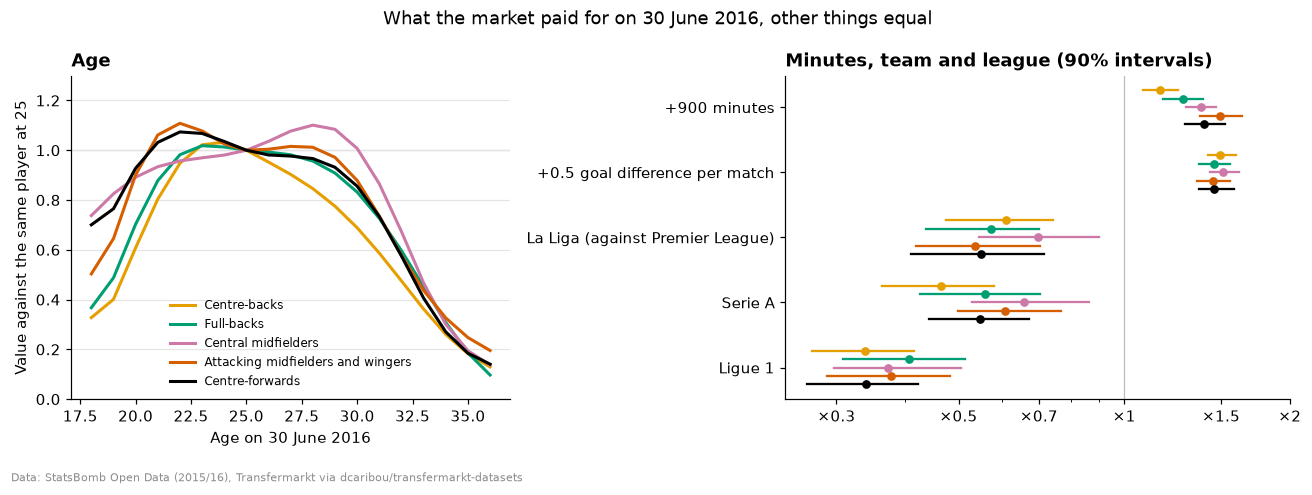

In [4]:
STEP = {"minutes": 900, TEAM: 0.5}  # ten full matches; half a goal per match
AGES = np.arange(18, 37)


def read(model, X):
    """Change in log value for each column's step; the age curve against age 25."""
    out = {
        c: np.diff(partial(model, X, c, [0.0, STEP.get(c, 1.0)]))[0]
        for c in X.columns
        if c != "age"
    }
    curve = partial(model, X, "age", AGES)
    return pd.Series(
        out | {f"age {a}": v for a, v in zip(AGES, curve - curve[AGES == 25][0], strict=True)}
    )


paid, paid_low, paid_high = {}, {}, {}
for g in OUTFIELD:
    columns = steps(g)[FULL]
    X, y = design[g][columns], players.log_value.loc[design[g].index]
    paid[g] = read(value_model(columns).fit(X, y), X)
    draws = team_bootstrap(
        lambda rows, X=X, y=y, columns=columns: read(
            value_model(columns).fit(X.iloc[rows], y.iloc[rows]), X
        ),
        players.team_id.loc[X.index],
    )
    paid_low[g], paid_high[g] = draws.quantile(0.05), draws.quantile(0.95)
paid, paid_low, paid_high = (np.exp(pd.DataFrame(d)) for d in (paid, paid_low, paid_high))

CONTEXT_ROWS = {
    "minutes": "+900 minutes",
    TEAM: "+0.5 goal difference per match",
    "La Liga": "La Liga (against Premier League)",
    "Serie A": "Serie A",
    "Ligue 1": "Ligue 1",
}
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.15]})
for i, g in enumerate(OUTFIELD):
    left.plot(
        AGES,
        paid.loc[[f"age {a}" for a in AGES], g],
        color=GROUP_COLORS[g],
        lw=2,
        label=GROUP_NAMES[g],
    )
    for j, row in enumerate(CONTEXT_ROWS):
        y = j + (i - 2) * 0.13
        right.plot(
            [paid_low.loc[row, g], paid_high.loc[row, g]], [y, y], color=GROUP_COLORS[g], lw=1.5
        )
        right.scatter(paid.loc[row, g], y, color=GROUP_COLORS[g], s=22, zorder=3)
left.axhline(1, color="#BBBBBB", lw=0.8, zorder=0)
left.set(xlabel="Age on 30 June 2016", ylabel="Value against the same player at 25", ylim=(0, 1.3))
left.set_title("Age")
left.legend(fontsize=8, loc="lower center")
right.axvline(1, color="#BBBBBB", lw=0.8, zorder=0)
right.set_xscale("log")
right.set_xticks([0.3, 0.5, 0.7, 1, 1.5, 2], labels=["×0.3", "×0.5", "×0.7", "×1", "×1.5", "×2"])
right.xaxis.set_minor_formatter(NullFormatter())
right.set_yticks(range(len(CONTEXT_ROWS)), labels=list(CONTEXT_ROWS.values()))
right.invert_yaxis()
right.grid(axis="y", visible=False)
right.set_title("Minutes, team and league (90% intervals)")
fig.suptitle("What the market paid for on 30 June 2016, other things equal", fontsize=12)
fig.tight_layout()
credit(fig)
plt.show()

**What the market paid for, other things equal:**

- **Age.** For the same numbers, values peak at 22 or 23, except among central midfielders (27
  to 28), and fall fast after 30: a 32-year-old is valued at half to two thirds (0.48 to 0.67)
  of the same player at 25, a 34-year-old at a quarter to a third. The ends of the curves rest on
  few players (29 under 20, 81 aged 34 or more).
- **Minutes.** Ten more full matches raise a value by 16% (centre-backs) to 49% (attacking
  midfielders and wingers).
- **The team.** Half a goal more of goal difference per match raises a value by 45% to 51%, in
  every group.
- **League.** The same player in La Liga or Serie A is valued at about half to two thirds (0.47
  to 0.70) of a Premier League player, in Ligue 1 at about a third (0.34 to 0.41).

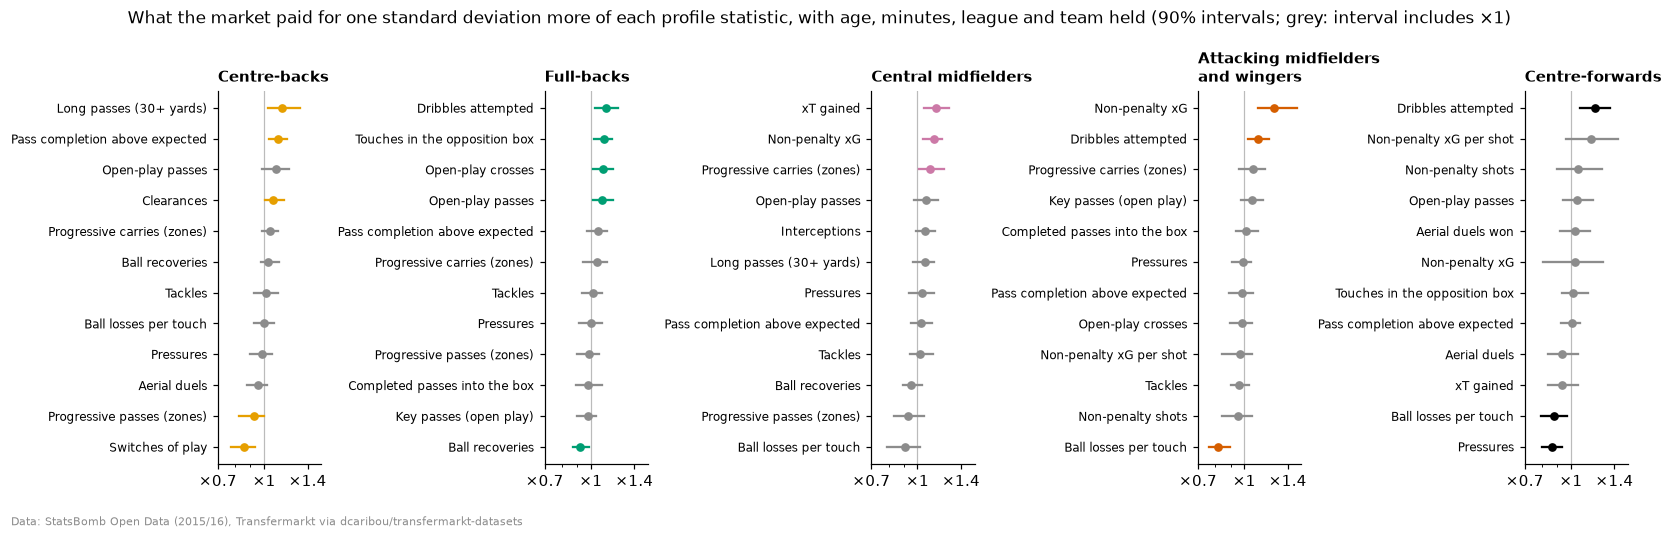

In [5]:
fig, axes = plt.subplots(1, len(OUTFIELD), figsize=(15, 4.6), sharex=True)
for ax, g in zip(axes, OUTFIELD, strict=True):
    stats = list(cfg.profiles[g])
    order = paid.loc[stats, g].sort_values().index
    for y, s in enumerate(order):
        clear = paid_low.loc[s, g] > 1 or paid_high.loc[s, g] < 1
        color = GROUP_COLORS[g] if clear else GREY
        ax.plot([paid_low.loc[s, g], paid_high.loc[s, g]], [y, y], color=color, lw=1.5)
        ax.scatter(paid.loc[s, g], y, color=color, s=22, zorder=3)
    ax.set_yticks(range(len(order)), labels=[LABELS[s] for s in order], fontsize=8)
    ax.axvline(1, color="#BBBBBB", lw=0.8, zorder=0)
    ax.grid(axis="y", visible=False)
    ax.set_title(GROUP_NAMES[g].replace(" and ", "\nand "), fontsize=10)
axes[0].set_xscale("log")
for ax in axes:
    ax.set_xticks([0.7, 1, 1.4], labels=["×0.7", "×1", "×1.4"])
    ax.xaxis.set_minor_formatter(NullFormatter())
fig.suptitle(
    "What the market paid for one standard deviation more of each profile statistic, with age, "
    "minutes, league and team held (90% intervals; grey: interval includes ×1)",
    fontsize=11,
)
fig.tight_layout()
credit(fig)
plt.show()

**Of the profile, the market paid for attacking output and the ball, not for defending.** With
age, minutes, league and team held, the statistics whose interval excludes ×1:

- **centre-backs:** long passes (×1.15 per standard deviation), completion above expected
  (×1.12) and clearances (×1.07); switches of play (×0.86) and progressive passes (×0.92) go the
  other way, but switches overlap with long passes and the two are best read together;
- **full-backs:** dribbles (×1.13), touches in the box (×1.11), crosses (×1.10) and passes
  (×1.09); ball recoveries the other way (×0.92);
- **central midfielders:** xT (×1.15), xG (×1.13) and progressive carries (×1.10);
- **attacking midfielders and wingers:** xG (×1.25) and dribbles (×1.12); ball losses per touch
  the other way (×0.82);
- **centre-forwards:** dribbles (×1.21); ball losses per touch (×0.88) and pressures (×0.87) the
  other way. No shooting statistic is clear on its own: xG is about shots times xG per shot, and
  the model splits what the three share.

Tackles, interceptions and pressures earn no premium in any group, and no statistic moves a value
by more than a quarter per standard deviation, against about half for half a goal of the team's
goal difference.

### 1.4 Valued below the numbers

A player's **gap** is the model's out-of-sample value less their value on 30 June 2016, on the
log scale: positive when other players with the same numbers were valued higher. Two versions:

- **within team**: the model with context, team and profile; the gap compares a player with
  others of the same age, minutes and league at teams of the same strength;
- **across teams**: context and profile, without the team; a player at a weak team with the
  numbers of players at strong teams shows a gap.

In [6]:
WITHIN, ACROSS = FULL, "Context + profile"
for name, model in (
    ("gap_within", WITHIN),
    ("gap_across", ACROSS),
    ("gap_context", "Context"),
    ("gap_team", "+ team"),
):
    players[name] = pd.concat([predicted[g, model] for g in OUTFIELD]) - players.log_value

display(
    by_group(
        pd.DataFrame(
            {
                "Within and across teams": players.groupby("comparison_group")[
                    ["gap_within", "gap_across"]
                ]
                .corr(method="spearman")
                .xs("gap_within", level=1)
                .gap_across,
                "Within teams, with team strength": players.groupby("comparison_group").apply(
                    lambda d: spearmanr(d.gap_within, d[TEAM]).statistic, include_groups=False
                ),
                "Across teams, with team strength": players.groupby("comparison_group").apply(
                    lambda d: spearmanr(d.gap_across, d[TEAM]).statistic, include_groups=False
                ),
            }
        )
    )
    .style.format("{:.2f}")
    .set_caption("Spearman correlations of the two gaps")
)

,Within and across teams,"Within teams, with team strength","Across teams, with team strength"
Centre-backs,0.76,-0.04,-0.52
Full-backs,0.83,-0.15,-0.57
Central midfielders,0.77,-0.05,-0.53
Attacking midfielders and wingers,0.84,-0.12,-0.46
Centre-forwards,0.80,-0.02,-0.50


**The two gaps agree on most players (0.76 to 0.84) and differ on the team.** Within team, the
gap is unrelated to the team's strength (−0.02 to −0.15). Across teams, it falls with it (−0.46
to −0.57): on average the model puts the players of the weakest fifth of teams at 1.7 times
their value, and those of the strongest fifth at 0.58 times. Without the team, a weak team's
player with good numbers is given the price those numbers fetch at strong teams.

In [7]:
def largest(gap, n=5, among=players):
    rows = []
    for g in OUTFIELD:
        top = among[among.comparison_group == g].nlargest(n, gap)
        for _, p in top.iterrows():
            rows.append(
                {
                    "Group": GROUP_NAMES[g],
                    "Player": p.known_as,
                    "Age": p.age,
                    "Club": p.club,
                    "Minutes": p.minutes,
                    "Value (€M)": p.value / 1e6,
                    "Model (€M)": p.value * np.exp(p[gap]) / 1e6,
                }
            )
    return pd.DataFrame(rows).set_index(["Group", "Player"]).rename_axis(index=[None, None])


for gap, title in (("gap_within", "within team"), ("gap_across", "across teams")):
    display(
        largest(gap)
        .style.format(
            {"Age": "{:.0f}", "Minutes": "{:,.0f}", "Value (€M)": "{:.1f}", "Model (€M)": "{:.1f}"}
        )
        .set_caption(f"The five largest gaps of each group, {title}")
    )

**Who the gaps point at.** Within team, three kinds of player lead:

- young players breaking through at strong teams (Iwobi, Iheanacho, Kevin Stewart, 598 to 854
  minutes), still valued as prospects in February;
- Leicester City's champions (Albrighton, Drinkwater, Wes Morgan), whose values were set in
  February, before the title;
- veterans (Gobbi at 36, Maxwell at 35, Camara at 34), whom the age curve cannot price as low as
  the market did.

Across teams, the list fills with regulars at small clubs: Bournemouth (Simon Francis, Adam
Smith, Surman, Arter, Joshua King), Las Palmas (Bigas, Aythami Artiles), Getafe, Espanyol,
Troyes, Empoli.

### 1.5 Does the gap know something the value did not?

Transfermarkt revalued most players between 30 June and 1 August 2016, after the season
(`01_data_exploration.ipynb`, section 4.3). If the gap is more than noise, players valued below
their numbers should have gone up more in that revaluation. The check takes the players whose
30 June value was set before the season ended and who were revalued by 1 August at the same club
(so neither the Euro 2016 squads' revaluation of 1 June nor a transfer is in it). The 1 August
values are read for this check only: the back-test measures value growth from 1 August, so that
this catch-up never counts as a prediction.

In [8]:
later = value_at(pool_valuations(con), cfg.backtest.outcome_base)
check = players.join(later[["value", "date", "club"]], rsuffix="_august")
check = check[
    ~check.after_season
    & (check.date > pd.Timestamp(cfg.backtest.market_view))
    & (check.club == check.club_august)
]
check["revalued"] = np.log(check.value_august / check.value)
GAPS = {
    "gap_context": "Context",
    "gap_team": "+ team",
    "gap_across": "Context + profile (across teams)",
    "gap_within": "+ team + profile (within team)",
}


def agreement(d):
    out = {label: spearmanr(d[gap], d.revalued).statistic for gap, label in GAPS.items()}
    return pd.Series(
        {"Players": len(d), "Minutes alone": spearmanr(d.minutes, d.revalued).statistic} | out
    )


per_group = check.groupby("comparison_group").apply(agreement, include_groups=False)
table = pd.concat([by_group(per_group), agreement(check).to_frame("All").T])
display(
    table.style.format("{:.2f}")
    .format("{:,.0f}", subset="Players")
    .set_caption("Spearman correlation with the revaluation of 30 June to 1 August 2016")
)

,Players,Minutes alone,Context,+ team,Context + profile (across teams),+ team + profile (within team)
Centre-backs,171,0.17,0.24,0.34,0.23,0.34
Full-backs,177,0.33,0.16,0.25,0.19,0.26
Central midfielders,217,0.17,0.26,0.44,0.33,0.43
Attacking midfielders and wingers,192,0.27,0.26,0.28,0.30,0.31
Centre-forwards,109,0.37,0.17,0.19,0.23,0.21
All,866,0.24,0.22,0.32,0.26,0.32


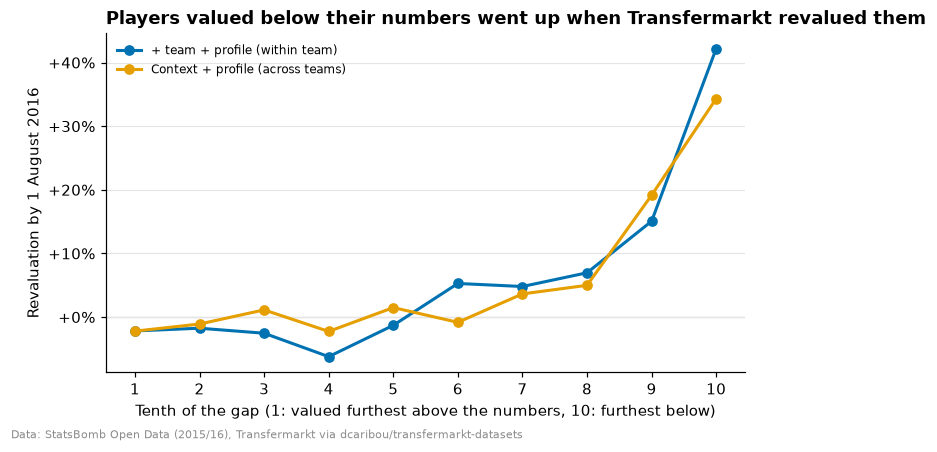

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for gap, color in (("gap_within", "#0072B2"), ("gap_across", "#E69F00")):
    tenth = pd.qcut(check[gap], 10, labels=False)
    change = np.exp(check.groupby(tenth).revalued.mean()) - 1
    ax.plot(range(1, 11), change, marker="o", color=color, lw=2, label=GAPS[gap])
ax.axhline(0, color="#BBBBBB", lw=0.8, zorder=0)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set(
    xticks=range(1, 11),
    xlabel="Tenth of the gap (1: valued furthest above the numbers, 10: furthest below)",
    ylabel="Revaluation by 1 August 2016",
)
ax.set_title("Players valued below their numbers went up when Transfermarkt revalued them")
ax.legend(fontsize=8)
credit(fig)
plt.show()

**The gap knows something the value did not.** Of the 866 players revalued at the same club
between 30 June and 1 August, the tenth with the largest gap within team went up 42% on average
and the next tenth 15%, while the half valued furthest above their numbers barely moved (−6% to
−1%). The gap within team agrees with the revaluation at 0.32 (Spearman), more than minutes
alone (0.24), which the revaluation was known to follow, or age, minutes and league (0.22). The
agreement comes from the team rather than the profile: context and team alone agree as well
(0.32), and the gap across teams less (0.26). This catch-up is Transfermarkt's lag and the
back-test does not count it; what remains to be seen is whether the gap still pays after 1
August.

### 1.6 Which gap the back-test reads first

The back-test (section 3) reads one gap first and keeps the other as a check, chosen here,
before any outcome is seen. A scout works under a budget, so the two are compared where a budget
puts them: the ten largest gaps of each group among players valued at €5M or less, an
illustrative ceiling, kept for the shortlists of section 4. Where the players play is read
by fifths of teams: the 80 teams in five groups of 16 by goal difference per match.

In [10]:
CEILING = 5e6
FIFTHS = ["1 (weakest)", "2", "3", "4", "5 (strongest)"]
players["team_fifth"] = players.team_id.map(
    pd.qcut(strength.rank(method="first"), 5, labels=FIFTHS)
)
affordable = players[players.value <= CEILING]
top = {
    gap: pd.concat(affordable[affordable.comparison_group == g].nlargest(10, gap) for g in OUTFIELD)
    for gap in ("gap_within", "gap_across")
}
shared = top["gap_within"][top["gap_within"].index.isin(top["gap_across"].index)]
display(
    by_group(
        pd.DataFrame(
            {
                "Players": affordable.groupby("comparison_group").size(),
                "Within team: median value (€M)": top["gap_within"]
                .groupby("comparison_group")
                .value.median()
                / 1e6,
                "Across teams: median value (€M)": top["gap_across"]
                .groupby("comparison_group")
                .value.median()
                / 1e6,
                "In both lists": shared.groupby("comparison_group")
                .size()
                .reindex(OUTFIELD, fill_value=0),
            }
        )
    )
    .style.format("{:.1f}")
    .format("{:,.0f}", subset=["Players", "In both lists"])
    .set_caption("The ten largest gaps of each group among players valued at €5M or less")
)
lists = {
    f"Players valued at €5M or less ({len(affordable)})": affordable,
    f"Ten largest gaps within team ({len(top['gap_within'])})": top["gap_within"],
    f"Ten largest gaps across teams ({len(top['gap_across'])})": top["gap_across"],
}
display(
    pd.DataFrame({name: d.team_fifth.value_counts(normalize=True) for name, d in lists.items()})
    .T[FIFTHS]
    .rename_axis(columns=None)
    .style.format("{:.0%}")
    .set_caption("Where they play: share by fifth of teams (goal difference per match), all groups")
)
display(
    largest("gap_within", among=affordable)
    .style.format(
        {"Age": "{:.0f}", "Minutes": "{:,.0f}", "Value (€M)": "{:.1f}", "Model (€M)": "{:.1f}"}
    )
    .set_caption("The five largest gaps within team of each group, players valued at €5M or less")
)

,Players,Within team: median value (€M),Across teams: median value (€M),In both lists
Centre-backs,193,1.5,1.5,4
Full-backs,188,0.8,0.8,8
Central midfielders,204,0.9,0.9,5
Attacking midfielders and wingers,172,0.9,0.6,7
Centre-forwards,99,2.0,2.0,5


,1 (weakest),2,3,4,5 (strongest)
Players valued at €5M or less (856),28%,24%,25%,17%,6%
Ten largest gaps within team (50),22%,12%,26%,18%,22%
Ten largest gaps across teams (50),50%,10%,26%,8%,6%


**Under a budget both gaps find cheap players; they differ on where those players play.** The
two lists of each group cost the same (a median of €0.6M to €2M) and share 4 to 8 of their ten
names. The list across teams takes half its players (25 of 50) from the weakest fifth of teams,
where 28% of the players under the ceiling play. The list within team spreads over the five
fifths (6 to 13 players each), so it takes more from the strongest fifth (11 of 50) than the 6%
of players under the ceiling who play there.

**The back-test reads the gap within team first.**

- The gap across teams mostly measures the team's strength (section 1.4), so a rule that picked
  the regulars of weak teams without looking at their numbers would make much the same list.
  Reading it first would test whether the market's discount for weak teams was too steep, not
  whether the profile finds players.
- The gap within team agrees more with Transfermarkt's own revaluation (0.32 against 0.26,
  section 1.5).

The gap across teams is kept as a check, and the bet it makes is tested directly: picking players
by their team's weakness alone is one of the back-test's baselines. The list within team also
shows what a budget misses, whether a player was for sale. Of its five largest gaps per group, 8
of 25 play for the strongest fifth of teams: among them prospects at Arsenal and Manchester City
(Iwobi, Iheanacho), a reserve at Real Madrid (Nacho) and Leicester City's champions still on
February values (Albrighton, Wes Morgan). Strong teams do not sell those players at their market
value, so the shortlists (section 4) also leave out the players of the strongest teams.

### What section 1 shows

- **Values on 30 June 2016 were mostly winter values**, a median 142 days old; one in eight, almost
  all from the Euro 2016 squads, was set after the season.
- **The market paid for the context and the team more than for the profile.** Age, minutes and
  league explain 29% to 43% of the variation in log value, the team's goal difference per match
  takes it to 62% to 73%, and the twelve profile statistics then add at most 0.03 (0.12 to 0.25
  without the team). Boosted trees do no better than a ridge regression.
- **What it paid:** a peak at 22 or 23 (27 to 28 for central midfielders) and half the value at
  32; 16% to 49% more for ten more full matches; 45% to 51% more for half a goal of goal
  difference per match; a half to two thirds of the Premier League's price in La Liga and Serie
  A, a third in Ligue 1. Within the profile, attacking output and the ball (xG, xT, dribbles,
  long passes, completion above expected), at most a quarter more per standard deviation; no
  premium for tackles, interceptions or pressures.
- **Two gaps between a player's numbers and their value:** within team, unrelated to the team's
  strength; across teams, mostly the team's strength (−0.46 to −0.57), which puts small clubs'
  regulars at the top.
- **The gap within team agrees with Transfermarkt's own revaluation after the season** (0.32;
  the top tenth went up 42%), through the team more than the profile. The back-test measures
  growth from 1 August 2016, after that catch-up.
- **The back-test reads the gap within team first.** Under a budget both gaps find cheap
  players; the gap across teams takes half of them from the weakest fifth of teams, a bet on the
  team that a baseline tests directly. The shortlists leave out the strongest teams' players, who
  were not for sale at their value.

## 2. What happened next

The back-test scores what happened to each profiled player after the market view, from
Transfermarkt: their value at four horizons (31 August 2017, 2018, 2019 and 2021: one, two, three
and five years on) against their value on 1 August 2016, after the end-of-season revaluation
(section 1.5), and their careers. This section fixes how those outcomes are scored before any
prediction is checked against them: it never reads the gaps or the profiles. The outcomes come
from `analysis.outcomes`.

In [11]:
outcomes = player_outcomes(con, cfg).join(
    players[["league", "known_as"]].add_suffix("_2016"), on="player_id"
)
base_year = cfg.backtest.outcome_base.year
HORIZON = {pd.Timestamp(h): f"+{h.year - base_year} ({h.year})" for h in cfg.backtest.horizons}
PRIMARY = pd.Timestamp(cfg.backtest.primary_horizon)
BANDS = list(outcomes.band.cat.categories)


def by_horizon(d):
    return d.rename(index=HORIZON, columns=HORIZON).rename_axis(index=None, columns=None)

### 2.1 Value growth against players of the same age

A player's growth at a horizon is the log ratio of their value then to their value on 1 August
2016. Raw growth is mostly age (`01_data_exploration.ipynb`, section 4.6), so it is scored as a
percentile among players of the same age band: two-year bands from 21 to 32, by age on 30 June
2016. Players no longer valued (no valuation in the 12 months before the horizon) tie at the
bottom of their band. A score of 50 is a typical career for the age. The check is excess
growth: growth less an age curve fitted on the players still valued.

In [12]:
def growth_summary(d):
    valued = d[d.still_valued]
    r2, _ = out_of_fold(
        lambda: value_model(["age"]), valued[["age"]], valued.growth, valued.player_id, repeats=5
    )
    return pd.Series(
        {
            "Players": len(d),
            "Still valued": valued.shape[0] / len(d),
            "Median value against 1 August 2016": np.exp(valued.growth.median()),
            "Growth explained by age (R²)": r2.mean(),
            "Score and excess growth (Spearman)": spearmanr(valued.score, valued.excess).statistic,
        }
    )


summary = outcomes.groupby("horizon").apply(growth_summary, include_groups=False)
scores = outcomes.pivot(index="player_id", columns="horizon", values="score")
summary["Score and the score three years on (Spearman)"] = scores.corr(method="spearman")[PRIMARY]
display(
    by_horizon(summary)
    .style.format("{:.2f}")
    .format("{:,.0f}", subset="Players")
    .format("{:.0%}", subset="Still valued")
    .format("×{:.2f}", subset="Median value against 1 August 2016")
    .set_caption("Value growth from 1 August 2016, the 1,335 profiled players (R² out of sample)")
)
print(
    "Players per age band:",
    outcomes[outcomes.horizon == PRIMARY].band.value_counts().reindex(BANDS).to_dict(),
)

,Players,Still valued,Median value against 1 August 2016,Growth explained by age (R²),Score and excess growth (Spearman),Score and the score three years on (Spearman)
+1 (2017),"1,335",98%,×1.00,0.24,0.98,0.55
+2 (2018),"1,335",96%,×0.86,0.33,0.97,0.80
+3 (2019),"1,335",92%,×0.75,0.38,0.95,1.00
+5 (2021),"1,335",81%,×0.38,0.43,0.93,0.71


Players per age band: {'under 21': 75, '21-22': 160, '23-24': 183, '25-26': 242, '27-28': 216, '29-30': 205, '31-32': 127, '33 and over': 127}


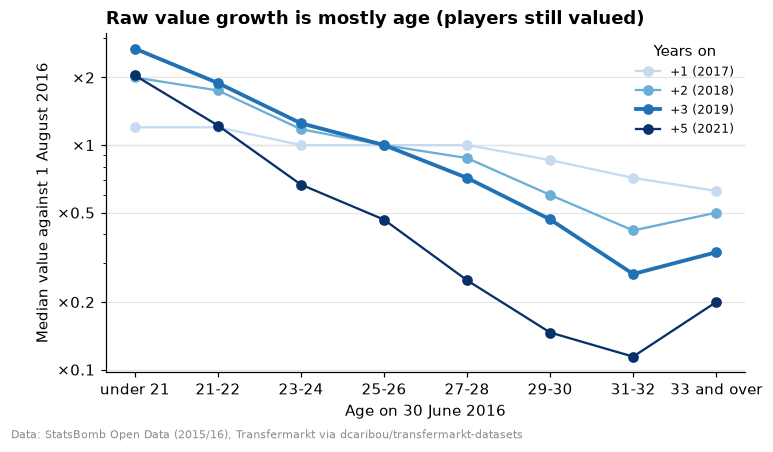

In [13]:
SHADES = dict(zip(HORIZON, ["#C6DBEF", "#6BAED6", "#2171B5", "#08306B"], strict=True))
fig, ax = plt.subplots(figsize=(7.5, 4))
for h, label in HORIZON.items():
    valued = outcomes[(outcomes.horizon == h) & outcomes.still_valued]
    median = np.exp(valued.groupby("band", observed=True).growth.median()).reindex(BANDS)
    ax.plot(
        range(len(BANDS)),
        median,
        marker="o",
        lw=2.5 if h == PRIMARY else 1.5,
        color=SHADES[h],
        label=label,
    )
ax.axhline(1, color="#BBBBBB", lw=0.8, zorder=0)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(lambda v, _: f"×{v:g}")
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_yticks([0.1, 0.2, 0.5, 1, 2])
ax.set(
    xticks=range(len(BANDS)),
    xticklabels=BANDS,
    xlabel="Age on 30 June 2016",
    ylabel="Median value against 1 August 2016",
)
ax.set_title("Raw value growth is mostly age (players still valued)")
ax.legend(title="Years on", fontsize=8)
credit(fig)
plt.show()

In [14]:
neutral = pd.concat(
    [
        outcomes.groupby(["comparison_group", "horizon"])
        .score.mean()
        .unstack()
        .reindex(OUTFIELD)
        .rename(index=GROUP_NAMES),
        outcomes.groupby(["league_2016", "horizon"]).score.mean().unstack().reindex(LEAGUES),
    ]
)
display(
    by_horizon(neutral)
    .style.format("{:.1f}")
    .set_caption("Mean score by comparison group and by league in 2015/16")
)

,+1 (2017),+2 (2018),+3 (2019),+5 (2021)
Centre-backs,50.9,51.6,50.4,50.7
Full-backs,51.9,50.4,48.4,50.1
Central midfielders,49.7,49.9,50.3,49.0
Attacking midfielders and wingers,49.3,49.8,52.0,51.0
Centre-forwards,49.7,49.8,50.0,51.3
Premier League,52.1,53.8,52.8,49.4
La Liga,45.4,45.1,48.8,51.8
Serie A,50.6,51.5,51.4,51.6
Ligue 1,53.2,51.1,48.4,48.5


**Age explains a quarter to two fifths of value growth, and the score takes it out.** One year
on, the median player still valued is worth what they were on 1 August 2016; five years on, 0.38
times as much. Players under 21 are worth 2.7 times as much three years on, players aged 31 or
32 a quarter (0.27), and the curve steepens with time: age explains 24% of growth at one year
and 43% at five, out of sample. The rest is what the back-test can hope to predict. (The oldest
band turns up because only its best players are still valued: 46% of it is gone three years
on, section 2.2.)

Among the players still valued, the score and excess growth rank players almost alike (Spearman
0.93 to 0.98), so the two differ only on the players no longer valued, whom the score places
without inventing a value. Scores drift with time: the score three years on agrees with the
score one year on at 0.55, two years on at 0.80 and five years on at 0.71. The score barely depends on position (48 to 52 on average) or league
(45 to 54): La Liga's players start lower over the first two years (45), the Premier League's
higher (52 to 54), and the difference is gone by five years.

### 2.2 Players no longer valued

A player with no valuation in the 12 months before a horizon is no longer valued: an outcome
(the back-test's dates, 2026-10-13), scored at the bottom of their band rather than left out.

In [15]:
gone = outcomes[~outcomes.still_valued]
shares = (
    (~outcomes.still_valued)
    .groupby([outcomes.band, outcomes.horizon], observed=True)
    .mean()
    .unstack()
)
shares.loc["All players"] = (~outcomes.still_valued).groupby(outcomes.horizon).mean()
display(
    by_horizon(shares)
    .style.format("{:.0%}")
    .set_caption("Share of players no longer valued, by age on 30 June 2016")
)

later = pool_valuations(con).groupby("player_id").date.max()
back = gone[gone.player_id.map(later) > gone.horizon]
counts = ", ".join(str(n) for n in gone.groupby("horizon").size())
ages = ", ".join(f"{a:.1f}" for a in gone.groupby("horizon").age.median())
returned = ", ".join(str(n) for n in back.groupby("horizon").size().reindex(HORIZON, fill_value=0))
everyone = outcomes.base[outcomes.horizon == PRIMARY].median()
print(
    f"No longer valued: {counts} players at the four horizons, "
    f"a median {ages} years old in 2016, last valued at a median €{gone.value.median() / 1e6:.1f}M "
    f"(all players on 1 August 2016: €{everyone / 1e6:.1f}M). "
    f"Valued again after the horizon: {returned}. "
    f"Last valued on 8 April 2020, the COVID cut: {(gone.date == '2020-04-08').sum()} at +5."
)
young = gone[(gone.horizon == max(HORIZON)) & (gone.age < 27)].sort_values("age")
display(
    young.set_index("known_as_2016")
    .rename_axis(index=None)[["age", "base", "value", "date", "club"]]
    .rename(
        columns={
            "age": "Age",
            "base": "Value 1 Aug 2016 (€M)",
            "value": "Last value (€M)",
            "date": "Last valued",
            "club": "Club then",
        }
    )
    .style.format(
        {
            "Age": lambda v: f"{int(v)}",
            "Value 1 Aug 2016 (€M)": lambda v: f"{v / 1e6:.1f}",
            "Last value (€M)": lambda v: f"{v / 1e6:.2f}",
            "Last valued": "{:%d %b %Y}",
        }
    )
    .set_caption("Players under 27 in 2016 no longer valued five years on")
)

,+1 (2017),+2 (2018),+3 (2019),+5 (2021)
under 21,0%,1%,1%,1%
21-22,1%,1%,1%,1%
23-24,0%,0%,0%,0%
25-26,0%,0%,1%,4%
27-28,1%,1%,2%,11%
29-30,0%,4%,7%,22%
31-32,3%,8%,19%,50%
33 and over,9%,27%,46%,83%
All players,2%,4%,8%,19%


No longer valued: 21, 58, 106, 250 players at the four horizons, a median 34.9, 34.0, 33.6, 32.5 years old in 2016, last valued at a median €0.5M (all players on 1 August 2016: €3.5M). Valued again after the horizon: 5, 10, 12, 11. Last valued on 8 April 2020, the COVID cut: 45 at +5.


,Age,Value 1 Aug 2016 (€M),Last value (€M),Last valued,Club then
Cameron Borthwick-Jackson,19,3.0,0.80,08 Apr 2020,Oldham Athletic
Iván López,22,0.9,0.20,23 Jul 2020,Retired
Manuel Pucciarelli,25,4.0,1.00,21 Aug 2020,Delfino Pescara 1936
Yacouba Sylla,25,1.5,0.25,05 Aug 2020,CFR Cluj
Emiliano Sala,25,2.0,16.00,17 Dec 2018,FC Nantes
Carlos Carbonero,25,3.0,0.72,08 Apr 2020,Without Club
Ignacio Camacho,26,10.0,1.00,08 Jul 2020,VfL Wolfsburg
Nabil Ghilas,26,1.8,0.33,08 Apr 2020,Vitória Setúbal FC
Abdoul Camara,26,1.2,1.00,04 Jun 2018,EA Guingamp
Aleksandar Tonev,26,0.8,0.33,08 Apr 2020,Botev Plovdiv


**Players who stop being valued are mostly veterans.** One player in five is no longer valued five
years on (250), half of those aged 31 or 32 in 2016 and 83% of those aged 33 and over; under 29,
at most 2% within three years. They were valued low when they dropped out (a median €0.5M,
against €3.5M for all players in August 2016) and few came back (5 to 12 valued again after the
horizon). Five years on, 45 of them were last valued on 8 April 2020, the COVID cut, and never
again.

Twelve players under 27 dropped out within five years: careers that went below Transfermarkt's
attention (Borthwick-Jackson at Oldham Athletic, Carbonero without a club) and one no scout
could foresee: Emiliano Sala, valued at €16M at Nantes a month before dying in January 2019.
Scored at the bottom of their band, players no longer valued matter most among the oldest, where
leaving is the norm: a veteran who kept playing ranks above one who retired.

### 2.3 Careers

At each horizon, what the player played in the season that had just ended (2016/17, 2017/18,
2018/19 and 2020/21), from Transfermarkt's appearances in the 14 first divisions it covers, their
cups and European competitions. A player's **level** is the league they played most league
minutes in: the big five, another covered league, or none (no league minutes in the covered
leagues); or no longer valued. A **regular** played 900 league minutes or more in the big five;
the Champions League counts any minute. Every profiled player played in the big five in 2015/16.

In [16]:
level_shares = (
    outcomes.groupby("horizon")["level"].value_counts(normalize=True).unstack()[list(LEVELS)]
)
level_shares.columns = [c.capitalize() for c in level_shares.columns]
level_shares["Regular in the big five"] = (
    (outcomes.big_five_minutes >= cfg.backtest.regular_minutes).groupby(outcomes.horizon).mean()
)
level_shares["Champions League"] = (
    (outcomes.champions_league_minutes > 0).groupby(outcomes.horizon).mean()
)
display(
    by_horizon(level_shares)
    .style.format("{:.0%}")
    .set_caption("Careers in the season before each horizon, the 1,335 profiled players")
)
country = (
    con.sql("SELECT competition_id, country_name FROM tm_competitions")
    .df()
    .set_index("competition_id")
    .country_name
)
other = outcomes[
    (outcomes.horizon == PRIMARY) & (outcomes.level == "other covered league")
].league.map(country)
print(
    "Other covered leagues at +3:", ", ".join(f"{c} {n}" for c, n in other.value_counts().items())
)

,Big five,Other covered league,No league minutes,No longer valued,Regular in the big five,Champions League
+1 (2017),79%,4%,16%,2%,62%,16%
+2 (2018),68%,7%,21%,4%,53%,18%
+3 (2019),57%,8%,27%,8%,44%,16%
+5 (2021),42%,9%,30%,19%,31%,14%


Other covered leagues at +3: Türkiye 50, Portugal 13, Greece 13, Russia 10, Belgium 9, Scotland 8, Netherlands 7, Denmark 1, Ukraine 1


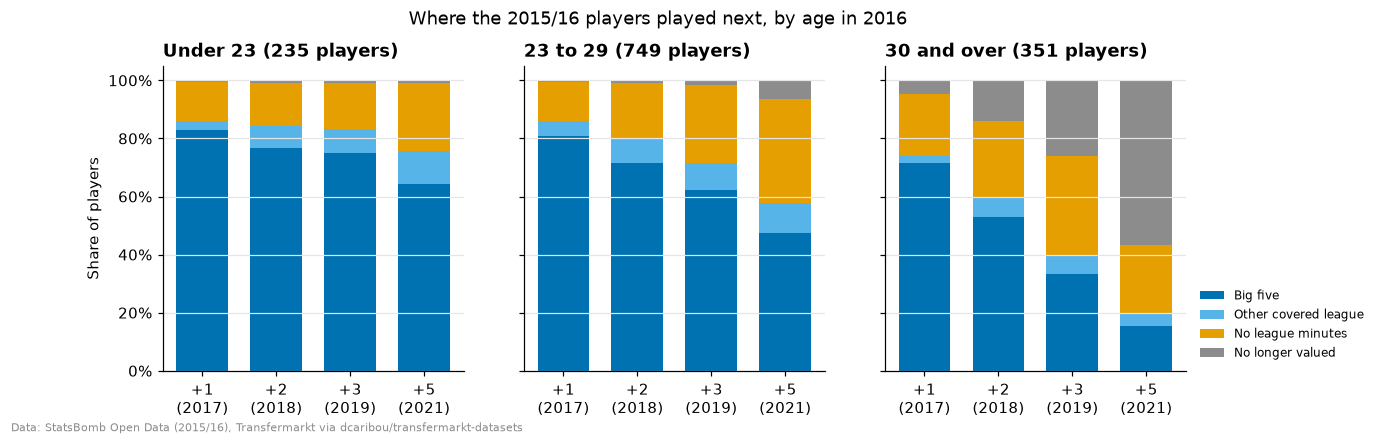

In [17]:
LEVEL_COLORS = dict(zip(LEVELS, ["#0072B2", "#56B4E9", "#E69F00", GREY], strict=True))
AGE_GROUPS = pd.cut(
    outcomes.age, [0, 23, 30, 99], right=False, labels=["Under 23", "23 to 29", "30 and over"]
)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (group, d) in zip(axes, outcomes.groupby(AGE_GROUPS, observed=True), strict=True):
    shares = (
        d.groupby("horizon")["level"].value_counts(normalize=True).unstack()[list(LEVELS)].fillna(0)
    )
    bottom = np.zeros(len(shares))
    for level in LEVELS:
        ax.bar(
            range(len(shares)),
            shares[level],
            bottom=bottom,
            color=LEVEL_COLORS[level],
            width=0.7,
            label=level.capitalize(),
        )
        bottom += shares[level].to_numpy()
    ax.set(
        xticks=range(len(shares)),
        xticklabels=[HORIZON[h].replace(" ", "\n") for h in shares.index],
        title=f"{group} ({d.player_id.nunique()} players)",
    )
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_ylabel("Share of players")
axes[-1].legend(fontsize=8, loc="lower left", bbox_to_anchor=(1.01, 0))
fig.suptitle("Where the 2015/16 players played next, by age in 2016", y=1.02)
credit(fig)
plt.show()

In [18]:
names, club_league = club_ids(con), club_leagues(con).set_index(["club_id", "season"]).league
valuations = pool_valuations(con)
minutes = season_minutes(con)
played = (
    minutes[minutes.type == "domestic_league"]
    .sort_values(["minutes", "competition_id"], ascending=[False, True])
    .drop_duplicates(["player_id", "season"])
    .set_index(["player_id", "season"])
    .competition_id
)


def league_of(club, season):
    """The league each club name (a Series by player) played in that season, by its club id."""
    return pd.Series(zip(club.map(names), [season] * len(club), strict=True), index=club.index).map(
        club_league
    )


rows, agree = {}, {}
for h in HORIZON:
    d = outcomes[outcomes.horizon == h].set_index("player_id")
    season_end = value_at(valuations, f"{h.year}-06-30").club.reindex(d.index)
    league_end = league_of(season_end, h.year - 1)
    out = d.level == "no league minutes"
    gone = season_end.isin(["Without Club", "Retired"])
    rows[h] = {
        "Players": out.sum(),
        "At a club of a covered league (no league minutes)": league_end[out].notna().mean(),
        "At a club of a covered league in other seasons": (
            season_end[out].map(names).notna() & league_end[out].isna()
        ).mean(),
        "At a club never in the covered leagues on record": (
            season_end[out].map(names).isna() & ~gone[out]
        ).mean(),
        "Without a club or retired": gone[out].mean(),
    }
    next_season = played.xs(h.year, level="season").reindex(d.index)
    agree[h] = {
        "end": (league_end == d.league)[d.league.notna()].mean(),
        "horizon": (league_of(d.club, h.year) == next_season)[
            next_season.notna() & d.still_valued
        ].mean(),
    }
display(
    by_horizon(pd.DataFrame(rows).T)
    .style.format("{:.0%}")
    .format("{:,.0f}", subset="Players")
    .set_caption(
        "Players with no league minutes in the covered leagues: their club at the end of the season"
    )
)
agree = pd.DataFrame(agree).T
print(
    "Players with league minutes: the club named on their value at the end of the season "
    f"(30 June) played in the league they played most in for {agree.end.min():.0%} to "
    f"{agree.end.max():.0%}; the club named at the horizon (31 August), against the season "
    f"that starts then, for {agree.horizon.min():.0%} to {agree.horizon.max():.0%}."
)

,Players,At a club of a covered league (no league minutes),At a club of a covered league in other seasons,At a club never in the covered leagues on record,Without a club or retired
+1 (2017),209,4%,67%,29%,0%
+2 (2018),275,6%,50%,43%,1%
+3 (2019),358,7%,42%,49%,1%
+5 (2021),405,5%,31%,60%,4%


Players with league minutes: the club named on their value at the end of the season (30 June) played in the league they played most in for 96% to 97%; the club named at the horizon (31 August), against the season that starts then, for 78% to 81%.


**Most players left the big five within five years, the young ones least.** One year on, 79%
played most of their league minutes in the big five; five years on, 42%, and 31% as regulars.
The rest moved to another covered league (4% to 9%, almost half of them to Turkey), played no league
minutes in the covered leagues (16% to 30%) or stopped being valued. Under 23, 64% were still in
the big five five years on; 30 and over, 15%. A sixth of the players (14% to 18%) played in the
Champions League each season.

Players without league minutes in the covered leagues were rarely on a covered club's bench (4%
to 7%). One year on, two thirds were at clubs that played in the covered leagues in other
seasons, in a lower division that season; with time, more were at clubs never on record in them
(60% five years on), such as clubs in Major League Soccer and China. The level is read from the
minutes, not the club named on the value: the club named at the end of the season matches the
league played for 96% to 97% of players, but the club named at the horizon matches the season
that starts then for only 78% to 81%, as a value can predate a summer move.

### 2.4 Do value and career agree?

If value growth is a fair summary of what happened, players who kept a place in the big five
should score high and those who dropped out of the covered leagues low.

In [19]:
agreement = (
    outcomes.groupby(["level", "horizon"])
    .score.mean()
    .unstack()
    .reindex(list(LEVELS))
    .rename(index=str.capitalize)
)
regular = outcomes.big_five_minutes >= cfg.backtest.regular_minutes
agreement.loc["Regular in the big five"] = outcomes[regular].groupby("horizon").score.mean()
agreement.loc["Not a regular in the big five"] = outcomes[~regular].groupby("horizon").score.mean()
agreement.loc["Champions League"] = (
    outcomes[outcomes.champions_league_minutes > 0].groupby("horizon").score.mean()
)
display(
    by_horizon(agreement)
    .style.format("{:.1f}")
    .set_caption("Mean score by career in the season before the horizon")
)
correlations = pd.DataFrame(
    {
        h: {
            "Big five league minutes": spearmanr(d.score, d.big_five_minutes).statistic,
            "Champions League minutes": spearmanr(d.score, d.champions_league_minutes).statistic,
        }
        for h, d in outcomes.groupby("horizon")
    }
)
display(
    by_horizon(correlations)
    .style.format("{:.2f}")
    .set_caption("Spearman correlation of the score with the season's minutes")
)

,+1 (2017),+2 (2018),+3 (2019),+5 (2021)
Big five,52.8,57.3,61.4,64.9
Other covered league,40.0,38.4,34.3,47.8
No league minutes,45.1,40.4,42.0,45.2
No longer valued,3.5,9.2,15.5,27.0
Regular in the big five,59.1,62.5,66.4,69.7
Not a regular in the big five,36.0,36.4,37.4,41.5
Champions League,56.9,63.5,63.6,68.5


,+1 (2017),+2 (2018),+3 (2019),+5 (2021)
Big five league minutes,0.45,0.51,0.54,0.50
Champions League minutes,0.11,0.23,0.21,0.27


**Value growth follows careers.** Players who stayed in the big five score above the middle, and
more so with time (53 one year on, 65 five years on); regulars score 59 to 70, the rest 36 to 42.
Players who moved to another covered league or out of the covered leagues score below the middle
(34 to 48), and those no longer valued at the bottom. The score agrees with big five league
minutes at 0.45 to 0.54 (Spearman), and Champions League players score 57 to 69. A rising value
is, on the whole, a career at the top level: the score is a fair primary outcome, and the levels
are secondary ones.

### What section 2 shows

- **Outcomes run from 1 August 2016**, read one, two, three and five years on; 92% of the
  profiled players are still valued three years on, 81% five years on.
- **Raw value growth is mostly age** (24% to 43% of it explained), so it is scored as a
  percentile within two-year age bands, players no longer valued at the bottom. The score ranks
  the players still valued like growth above an age curve (0.93 to 0.98) and barely depends on
  position or league.
- **Players no longer valued are mostly veterans** (83% of those 33 and over five years on), valued
  low when they left, and rarely come back.
- **Careers:** 79% of players were in the big five one year on, 42% five years on; the young
  stayed most (64% of those under 23).
- **Value and career agree:** big five regulars score 59 to 70, the rest 36 to 42.
- **The back-test reads the score three years on (31 August 2019) first**: before the COVID cut,
  with 92% still valued and the young near their peak growth. The other horizons and the careers
  support it.

## 3. The back-test

Did the players valued furthest below their numbers on 30 June 2016 do better than players of
their age? Everything below was fixed before any result was seen:

- **the system's ranking** is the gap within team (section 1.6), out of sample: every player's
  gap comes from a model that never saw their team;
- **the pick** is the top 10% of each comparison group, 133 players;
- **the outcome** is the pick's mean score three years on (31 August 2019, section 2), where 50
  is a typical career for the age; one, two and five years on, and the careers, support it;
- **baselines**, rules a club could have used without the profiles, pick as many players per
  group: the most minutes in 2015/16, the cheapest on 30 June 2016, the youngest, and the
  weakest teams' players (by the team's goal difference per match, most minutes first);
- **checks**: the gap across teams and the gap of the model without the profile (context and
  team only), which shows what the twelve statistics add;
- **intervals** (90%) come from 200 resamples of whole 2015/16 teams, the picks made afresh in
  each; differences between rankings are read on the same resamples.

In [20]:
SHARE = 0.1
SCORE = {h: f"score_{h.year}" for h in HORIZON}
data = players.join(
    outcomes.pivot(index="player_id", columns="horizon", values="score").rename(columns=SCORE)
)
KEYS = {
    "Gap within team": lambda d: d.gap_within,
    "Gap without the profile": lambda d: d.gap_team,
    "Gap across teams": lambda d: d.gap_across,
    "Most minutes": lambda d: d.minutes,
    "Cheapest": lambda d: -d.value,
    "Youngest": lambda d: -d.age,
    "Weakest teams": lambda d: lexicographic(-d.team_goal_difference, d.minutes),
}
SYSTEM, CHECKS = "Gap within team", ["Gap without the profile", "Gap across teams"]
picks = pd.DataFrame(
    {name: pick_weights(key(data), data.comparison_group, SHARE) for name, key in KEYS.items()}
)


def judged(d, score=SCORE[PRIMARY]):
    """Each ranking's pick's mean score, and every player's."""
    return pd.concat(
        [pick_means(d, KEYS, score, SHARE), pd.Series({"All players": d[score].mean()})]
    )


draws = {
    h: team_bootstrap(lambda rows, s=s: judged(data.iloc[rows], s), data.team_id)
    for h, s in SCORE.items()
}
print(
    f"Picks: {picks[SYSTEM].sum():.0f} players,",
    picks[SYSTEM].groupby(data.comparison_group).sum().reindex(OUTFIELD).astype(int).to_dict(),
)

Picks: 133 players, {'CB': 26, 'FB': 27, 'CM': 32, 'AMW': 30, 'CF': 18}


### 3.1 The picks against the baselines

,Mean score,"90% interval, low",high,Gap within team ahead by,"90% interval, low",high,Players shared with the system's pick
Gap within team,62.6,55.7,68.3,,,,133
Gap without the profile,61.3,55.8,67.9,1.3,-2.6,3.7,99
Gap across teams,59.4,54.2,66.3,3.2,-1.6,5.6,81
Most minutes,61.7,57.8,65.9,0.9,-5.9,5.6,16
Cheapest,53.4,48.8,59.2,9.2,2.7,15.2,47
Youngest,52.1,48.5,56.8,10.5,3.4,15.3,21
Weakest teams,47.3,42.6,50.3,15.3,8.6,21.9,11
All players,50.3,48.7,51.9,12.3,6.1,17.0,


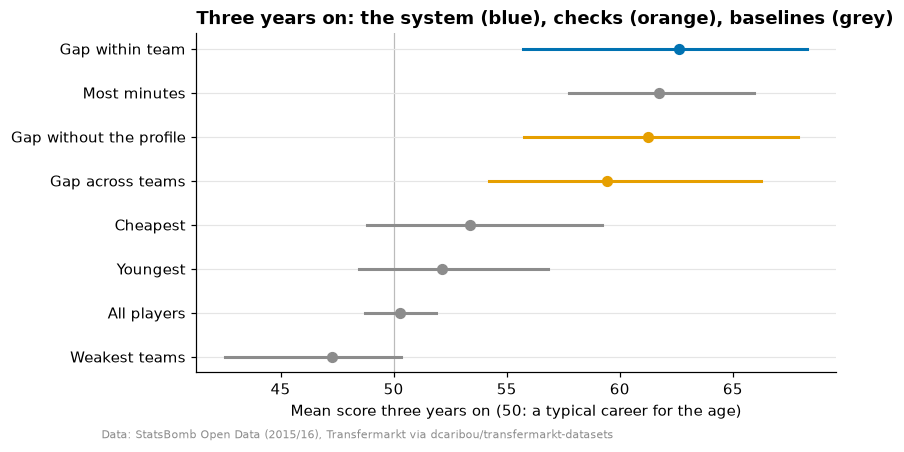

In [21]:
point, sample = judged(data), draws[PRIMARY]
ahead = sample.rsub(sample[SYSTEM], axis=0)
table = pd.DataFrame(
    {
        "Mean score": point,
        "90% interval, low": sample.quantile(0.05),
        "high": sample.quantile(0.95),
        "Gap within team ahead by": point[SYSTEM] - point,
        "90% interval, low ": ahead.quantile(0.05),
        "high ": ahead.quantile(0.95),
        "Players shared with the system's pick": (
            (picks > 0) & (picks[[SYSTEM]].to_numpy() > 0)
        ).sum(),
    }
).reindex(point.index)
table.loc[SYSTEM, ["Gap within team ahead by", "90% interval, low ", "high "]] = np.nan
table.loc["All players", "Players shared with the system's pick"] = np.nan
display(
    table.style.format("{:.1f}", na_rep="")
    .format("{:.0f}", subset="Players shared with the system's pick", na_rep="")
    .set_caption(
        "Mean score three years on (31 August 2019) of each ranking's pick, top 10% of each group"
    )
)

order = point.sort_values().index
kind_color = {
    name: "#0072B2" if name == SYSTEM else "#E69F00" if name in CHECKS else GREY for name in order
}
fig, ax = plt.subplots(figsize=(7.5, 4))
for i, name in enumerate(order):
    ax.plot(
        [sample[name].quantile(0.05), sample[name].quantile(0.95)],
        [i, i],
        color=kind_color[name],
        lw=2,
    )
    ax.scatter(point[name], i, color=kind_color[name], s=40, zorder=3)
ax.axvline(50, color="#BBBBBB", lw=0.8, zorder=0)
ax.set(
    yticks=range(len(order)),
    yticklabels=order,
    xlabel="Mean score three years on (50: a typical career for the age)",
)
ax.set_title("Three years on: the system (blue), checks (orange), baselines (grey)")
credit(fig)
save(fig, "backtest_baselines", cfg)
plt.show()

**The system's pick did better than players of its age, but no better than picking the
regulars.** Three years on, the 133 players with the largest gap within team rank on average at
the 63rd percentile of their age band (62.6, 90% interval 55.7 to 68.3), 12.3 points above all
players (6.1 to 17.0). The most-minutes rule does about as well (61.7; the gap ahead by 0.9,
-5.9 to 5.6) with a different set of players (16 shared), and so does the model without the
profile (61.3; ahead by 1.3, -2.6 to 3.7) with much the same players (99 shared): the twelve
statistics add nothing that can be told from chance. The gap across teams is a little behind
(59.4). Cheap or young players alone do little better than the average (53.4 and 52.1), and the
weakest teams' regulars do worse (47.3, 42.6 to 50.3); the gap within team is ahead of them by
15.3 points (8.6 to 21.9).

### 3.2 The whole ranking

The pick reads only the top of the ranking. How the score follows the whole of it: the Spearman
correlation within each group, and the mean score by tenth of the group's ranking.

,Gap within team,Gap without the profile,Gap across teams,Most minutes
Centre-backs,0.16,0.18,0.02,0.13
Full-backs,0.08,0.07,0.05,0.13
Central midfielders,0.17,0.14,0.12,0.13
Attacking midfielders and wingers,0.16,0.11,0.13,0.17
Centre-forwards,0.14,0.14,0.07,0.15
All (within groups),0.15,0.13,0.08,0.14


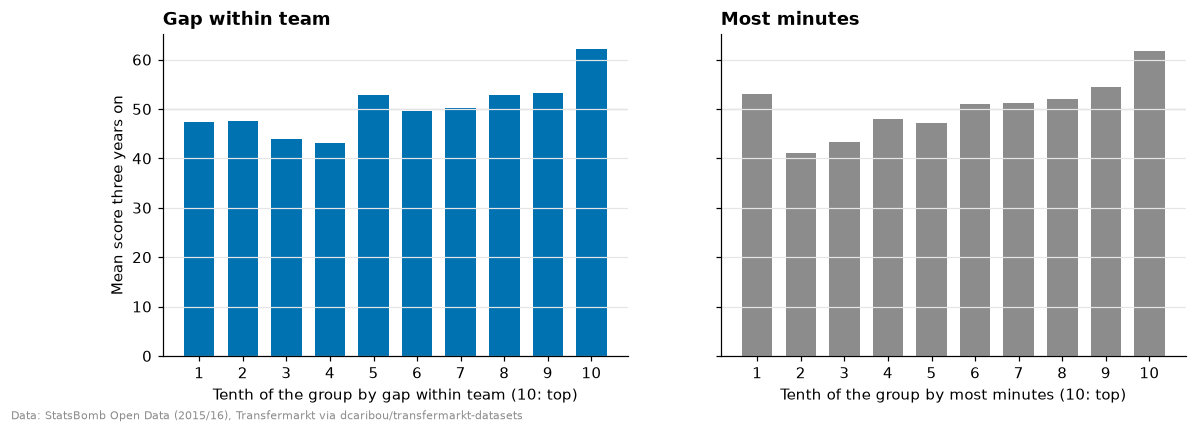

In [22]:
def within_groups(name, transform):
    """`transform` applied to a ranking's key within each comparison group."""
    return pd.concat(
        [transform(KEYS[name](d)) for _, d in data.groupby("comparison_group")]
    ).reindex(data.index)


whole = {}
for g, d in data.groupby("comparison_group"):
    whole[GROUP_NAMES[g]] = {
        name: spearmanr(KEYS[name](d), d[SCORE[PRIMARY]]).statistic
        for name in [SYSTEM, *CHECKS, "Most minutes"]
    }
whole["All (within groups)"] = {
    name: spearmanr(within_groups(name, lambda k: k.rank(pct=True)), data[SCORE[PRIMARY]]).statistic
    for name in [SYSTEM, *CHECKS, "Most minutes"]
}
display(
    pd.DataFrame(whole)
    .T.reindex([GROUP_NAMES[g] for g in OUTFIELD] + ["All (within groups)"])
    .style.format("{:.2f}")
    .set_caption("Spearman correlation of each ranking with the score three years on")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, color) in zip(axes, [(SYSTEM, "#0072B2"), ("Most minutes", GREY)], strict=True):
    tenth = within_groups(name, lambda k: pd.qcut(k.rank(method="first"), 10, labels=False) + 1)
    means = data.groupby(tenth)[SCORE[PRIMARY]].mean()
    ax.bar(means.index, means, color=color, width=0.7)
    ax.axhline(50, color="#BBBBBB", lw=0.8, zorder=0)
    ax.set(
        xticks=range(1, 11), xlabel=f"Tenth of the group by {name.lower()} (10: top)", title=name
    )
axes[0].set_ylabel("Mean score three years on")
credit(fig)
plt.show()

**The signal sits at the top of the ranking.** Within groups the gap correlates with the score at
only 0.15 (0.08 to 0.17 by group), about as much as minutes (0.14). By tenths of the gap, the
bottom four score 43 to 48 on average, the middle five 50 to 53, and only the top tenth stands out
(62). A ranking that works at the top is what a shortlist needs, but the system's worth lies in
its strongest calls, not in ordering the whole league.

### 3.3 The gap and minutes

,Players,Median value (€M),Median minutes,Median age,Mean score three years on
Gap within team,133,1.2,"1,642",26.3,62.6
Most minutes,133,6.0,"3,251",26.8,61.7
In both,16,3.0,"3,243",29.6,76.3
Gap within team only,117,1.0,"1,500",25.8,60.7
Most minutes only,117,7.5,"3,256",26.8,59.7


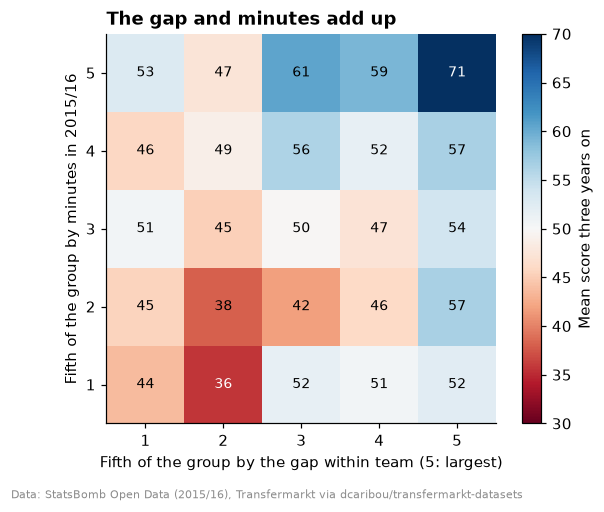

Score points from the bottom to the top of the group, both rankings in one regression: minutes 14.3 (10.5 to 17.6); gap 14.8 (10.5 to 19.5). Spearman of the gap with minutes within groups: -0.02.


In [23]:
system, minutes_pick = picks[SYSTEM] > 0, picks["Most minutes"] > 0
lists = {
    "Gap within team": system,
    "Most minutes": minutes_pick,
    "In both": system & minutes_pick,
    "Gap within team only": system & ~minutes_pick,
    "Most minutes only": minutes_pick & ~system,
}
display(
    pd.DataFrame(
        {
            name: {
                "Players": rows.sum(),
                "Median value (€M)": data.value[rows].median() / 1e6,
                "Median minutes": data.minutes[rows].median(),
                "Median age": data.age[rows].median(),
                "Mean score three years on": data[SCORE[PRIMARY]][rows].mean(),
            }
            for name, rows in lists.items()
        }
    )
    .T.style.format("{:.1f}")
    .format("{:,.0f}", subset=["Players", "Median minutes"])
    .set_caption("The gap's pick and the minutes' pick")
)


def fifth(column):
    return data.groupby("comparison_group")[column].transform(
        lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1
    )


grid = data.groupby([fifth("minutes"), fifth("gap_within")])[SCORE[PRIMARY]].mean().unstack()
fig, ax = plt.subplots(figsize=(6, 4.6))
image = ax.imshow(grid, origin="lower", cmap="RdBu", vmin=30, vmax=70)
for (i, j), v in np.ndenumerate(grid.to_numpy()):
    ax.text(
        j,
        i,
        f"{v:.0f}",
        ha="center",
        va="center",
        fontsize=9,
        color="white" if abs(v - 50) > 12 else "black",
    )
ax.set(
    xticks=range(5),
    xticklabels=range(1, 6),
    yticks=range(5),
    yticklabels=range(1, 6),
    xlabel="Fifth of the group by the gap within team (5: largest)",
    ylabel="Fifth of the group by minutes in 2015/16",
)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Mean score three years on")
ax.set_title("The gap and minutes add up")
credit(fig)
plt.show()


def additive(d):
    """Score on the player's rank within group (0 to 1) by minutes and by the gap."""
    ranks = d.groupby("comparison_group")[["minutes", "gap_within"]].rank(pct=True)
    X = np.column_stack([np.ones(len(d)), ranks.minutes, ranks.gap_within])
    return pd.Series(
        np.linalg.lstsq(X, d[SCORE[PRIMARY]], rcond=None)[0][1:], index=["minutes", "gap"]
    )


minutes_rank = data.groupby("comparison_group").minutes.rank(pct=True)
gap_rank = data.groupby("comparison_group").gap_within.rank(pct=True)
independence = spearmanr(gap_rank, minutes_rank).statistic
fit, fits = (
    additive(data),
    team_bootstrap(lambda rows: additive(data.iloc[rows].reset_index(drop=True)), data.team_id),
)
print(
    "Score points from the bottom to the top of the group, both rankings in one regression: "
    + "; ".join(
        f"{k} {fit[k]:.1f} ({fits[k].quantile(0.05):.1f} to {fits[k].quantile(0.95):.1f})"
        for k in fit.index
    )
    + f". Spearman of the gap with minutes within groups: {independence:.2f}."
)

**The gap and minutes pick different players, and their signals add up.** The gap's pick is cheap
(a median €1.2M against €6.0M) and played less (1,642 minutes against 3,251). Each pick without
the other scores about 60; the 16 players in both score 76. Within groups the gap is unrelated to
minutes (Spearman -0.02, as the value model holds minutes fixed), and in one regression each is
worth about 15 points of score from the bottom of the group to the top (minutes 14.3, 90%
interval 10.5 to 17.6; the gap 14.8, 10.5 to 19.5). Players in the top fifth of both score 71.
This was found after the results: it is a finding of the back-test, not a ranking tested on its
own.

### 3.4 Other horizons and careers

In [24]:
horizons = pd.DataFrame({h: judged(data, s) for h, s in SCORE.items()}).astype(object)


def interval(values):
    return f"{values.quantile(0.05):.1f} to {values.quantile(0.95):.1f}"


horizons.loc["Gap within team, 90% interval"] = {h: interval(draws[h][SYSTEM]) for h in HORIZON}
for other in ["Gap without the profile", "Most minutes"]:
    horizons.loc[f"Ahead of {other.lower()}"] = {
        h: horizons.loc[SYSTEM, h] - horizons.loc[other, h] for h in HORIZON
    }
    horizons.loc[f"Ahead of {other.lower()}, 90% interval"] = {
        h: interval(draws[h][SYSTEM] - draws[h][other]) for h in HORIZON
    }
display(
    by_horizon(horizons)
    .style.format(lambda v: v if isinstance(v, str) else f"{v:.1f}")
    .set_caption("Mean score of each ranking's pick at every horizon")
)

at_primary = outcomes[outcomes.horizon == PRIMARY].set_index("player_id").reindex(data.index)
career_flags = pd.DataFrame(
    {
        "Regular in the big five": at_primary.big_five_minutes >= cfg.backtest.regular_minutes,
        "Champions League": at_primary.champions_league_minutes > 0,
        "No longer valued": ~at_primary.still_valued,
    }
).astype(float)
expected = career_flags.groupby(at_primary.band, observed=True).transform("mean")
careers = pd.DataFrame(
    {
        name: {
            (flag, column): np.average(values[flag], weights=picks[name])
            for flag in career_flags
            for column, values in (("Pick", career_flags), ("Expected for their ages", expected))
        }
        for name in [SYSTEM, "Gap without the profile", "Most minutes"]
    }
).T
display(
    careers.style.format("{:.0%}").set_caption(
        "Careers of the picks in 2018/19 against players of their age bands"
    )
)

,+1 (2017),+2 (2018),+3 (2019),+5 (2021)
Gap within team,63.6,63.4,62.6,60.0
Gap without the profile,62.3,61.0,61.3,57.4
Gap across teams,62.0,58.0,59.4,55.4
Most minutes,59.8,61.5,61.7,59.6
Cheapest,58.1,56.0,53.4,53.2
Youngest,51.9,53.2,52.1,51.4
Weakest teams,47.7,44.8,47.3,49.8
All players,50.3,50.3,50.3,50.3
"Gap within team, 90% interval",57.5 to 68.5,56.8 to 68.3,55.7 to 68.3,53.4 to 64.8
Ahead of gap without the profile,1.3,2.4,1.3,2.5


**The result holds at every horizon, and the values grew without a step up in career.** The gap's
pick scores 60 to 64 one to five years on, ahead of the model without the profile by 1.3 to 2.5
points and of the minutes rule by 0.4 to 3.8, never clearly. In 2018/19 its players' careers were
those of players their age: 44% regulars in the big five (46% expected from their age bands), 5%
in the Champions League (17% expected). The minutes rule's players kept their places: 72%
regulars (45% expected), 26% in the Champions League. The gap found players whose value caught
up with their numbers rather than players who moved up: a pick for buying below value, not for
finding the next star.

### What section 3 shows

- **The system's pick did better than players of its age**: the top 10% of each group by the gap
  within team, 133 players, rank on average at the 63rd percentile of their age band three years
  on (90% interval 56 to 68), and at 60 to 64 at every horizon.
- **A simple rule did as well**: the players with the most minutes in 2015/16 score 61.7. Cheap or
  young players alone are close to average (53.4, 52.1), the weakest teams' regulars below it
  (47.3).
- **The profile adds nothing detectable to the gap**: the model without the twelve statistics
  picks 99 of the same 133 players and scores 61.3. The gap's edge comes from the market pricing
  a player below players of the same age, minutes, league and team.
- **The gap and minutes are independent and add up**: about 15 points of score each from the
  bottom of the group to the top; the 16 players in both picks score 76.
- **The gap's players kept careers typical for their age** (44% big five regulars, 46%
  expected): their value caught up with their numbers rather than their careers moving up.

## 4. Shortlists

What a club could have done with the system on 30 June 2016: a shortlist for each position, within
a budget, of players their clubs would sell. The rules were set before the shortlists' outcomes
were looked at:

- **budget**: valued at €5M or less on 30 June 2016, the ceiling of section 1.6;
- **for sale**: the players of the strongest fifth of teams are left out, as strong teams do not
  sell their prospects and regulars at their market value (section 1.6);
- **ranking**: the gap within team, as in the back-test, with minutes in 2015/16 shown next to
  each name. The gap and minutes together did best in section 3.3, but that was found after the
  results and no later season is left to test it on, so it does not rank the shortlists;
- **length**: five players per group, 25 in all;
- **judged** as the back-test: the mean score three years on, against every player within the
  budget and the shortlists of the gap without the profile and of the most minutes, with 90%
  intervals from 200 resamples of whole teams.

### 4.1 The shortlists

What a scout would have read on 30 June 2016: each player's club on that date, the fifth of teams
they played for (by goal difference per match), their minutes, their value, and the value the
model gives players with their numbers (out of sample).

In [25]:
BUDGET, PLACES = 5e6, 5
available = data[(data.value <= BUDGET) & (data.team_fifth != FIFTHS[-1])]
on_list = pick_weights(available.gap_within, available.comparison_group, places=PLACES) > 0
shortlist = pd.concat(
    available[on_list & (available.comparison_group == g)].sort_values(
        "gap_within", ascending=False
    )
    for g in OUTFIELD
)
group_median = data.groupby("comparison_group").minutes.median()
regular = shortlist.minutes >= shortlist.comparison_group.map(group_median)


def by_player(d):
    """Rows indexed by group and player name, as in the tables of section 1."""
    return d.set_index(
        [d.index.map(data.comparison_group).map(GROUP_NAMES), d.index.map(data.known_as)]
    ).rename_axis(index=[None, None])


display(
    by_player(
        pd.DataFrame(
            {
                "Age": shortlist.age,
                "Club": shortlist.club,
                "Team's fifth": shortlist.team_fifth,
                "Minutes": shortlist.minutes,
                "Value (€M)": shortlist.value / 1e6,
                "Model (€M)": shortlist.value * np.exp(shortlist.gap_within) / 1e6,
            }
        )
    )
    .style.format(
        {
            "Age": lambda v: f"{int(v)}",
            "Minutes": "{:,.0f}",
            "Value (€M)": "{:.1f}",
            "Model (€M)": "{:.1f}",
        }
    )
    .set_caption(
        "The shortlists on 30 June 2016: the five largest gaps within team of each group, "
        "players valued at €5M or less outside the strongest fifth of teams"
    )
)
sizes = ", ".join(
    f"{g} {n}" for g, n in available.comparison_group.value_counts().reindex(OUTFIELD).items()
)
fifths = ", ".join(str(n) for n in shortlist.team_fifth.value_counts().reindex(FIFTHS[:-1]))
fifths_all = ", ".join(
    f"{s:.0%}" for s in available.team_fifth.value_counts(normalize=True).reindex(FIFTHS[:-1])
)
print(
    f"{len(available)} players within the budget and available ({sizes}). The shortlist: a median "
    f"value of €{shortlist.value.median() / 1e6:.1f}M (all available: "
    f"€{available.value.median() / 1e6:.1f}M), a median age of {shortlist.age.median():.1f} "
    f"({available.age.median():.1f}), {regular.sum()} of {len(shortlist)} at or above their "
    f"group's median minutes; by fifth of teams {fifths} (all available: {fifths_all})."
)

808 players within the budget and available (CB 178, FB 176, CM 193, AMW 165, CF 96). The shortlist: a median value of €0.6M (all available: €2.0M), a median age of 24.5 (27.4), 8 of 25 at or above their group's median minutes; by fifth of teams 6, 3, 9, 7 (all available: 30%, 26%, 27%, 18%).


**The shortlists are young, cheap and short of minutes.** Of the 808 players within the budget and
outside the strongest teams, the 25 shortlisted were valued at a median €0.6M (€2.0M for all 808)
and were a median 24.5 years old (27.4); 8 had played their group's median minutes or more. The
model values them at 3 to 13 times their value. They come from every fifth of teams below the
strongest (6, 3, 9 and 7 players) and include prospects (Ludovic Blas at 18, Issa Diop at 19,
Lorenzo Pellegrini at 20), regulars at small clubs (Adam Smith and Andrew Surman at Bournemouth)
and veterans (Massimo Gobbi at 35, Momo and Souleymane Camara at 33). Kevin Stewart, 598 minutes
at Liverpool, has the largest gap (the model's value 12.6 times the market's). Sebastián Coates is listed
at Sporting CP, which Coates joined from Sunderland in January.

### 4.2 How the shortlists did

In [26]:
SHORTLIST_KEYS = {name: KEYS[name] for name in [SYSTEM, "Gap without the profile", "Most minutes"]}
EVERYONE = "All players within the budget"


def shortlisted(d, score=SCORE[PRIMARY], places=PLACES):
    """Each ranking's shortlist's mean score, and every available player's."""
    return pd.concat(
        [
            pick_means(d, SHORTLIST_KEYS, score, places=places),
            pd.Series({EVERYONE: d[score].mean()}),
        ]
    )


short_point = shortlisted(available)
short_draws = team_bootstrap(lambda rows: shortlisted(available.iloc[rows]), available.team_id)
short_ahead = short_draws.rsub(short_draws[SYSTEM], axis=0)
short_picks = pd.DataFrame(
    {
        name: pick_weights(key(available), available.comparison_group, places=PLACES) > 0
        for name, key in SHORTLIST_KEYS.items()
    }
)
table = pd.DataFrame(
    {
        "Mean score": short_point,
        "90% interval, low": short_draws.quantile(0.05),
        "high": short_draws.quantile(0.95),
        "Gap within team ahead by": short_point[SYSTEM] - short_point,
        "90% interval, low ": short_ahead.quantile(0.05),
        "high ": short_ahead.quantile(0.95),
        "Players shared with the shortlist": (short_picks & short_picks[[SYSTEM]].to_numpy()).sum(),
    }
)
table.loc[SYSTEM, ["Gap within team ahead by", "90% interval, low ", "high "]] = np.nan
display(
    table.style.format("{:.1f}", na_rep="")
    .format("{:.0f}", subset="Players shared with the shortlist", na_rep="")
    .set_caption(
        "Mean score three years on (31 August 2019) of each ranking's shortlist, five per group"
    )
)

other = {}
for budget in (2e6, 5e6, 10e6):
    d = data[(data.value <= budget) & (data.team_fifth != FIFTHS[-1])]
    for places in (5, 10):
        other[f"€{budget / 1e6:.0f}M", places] = shortlisted(d, places=places)
display(
    pd.DataFrame(other)
    .rename_axis(columns=["Budget", "Players per group"])
    .style.format("{:.1f}")
    .set_caption("Mean score three years on under other budgets and shortlist lengths")
)
display(
    by_horizon(pd.DataFrame({h: shortlisted(available, s) for h, s in SCORE.items()}))
    .style.format("{:.1f}")
    .set_caption("Mean score of each ranking's shortlist at every horizon")
)
revalued = outcomes[outcomes.horizon == PRIMARY].set_index("player_id").base / data.value
short_score = shortlist[SCORE[PRIMARY]]
print(
    f"Shortlisted at or above their group's median minutes: {regular.sum()} players, a mean "
    f"score of {short_score[regular].mean():.1f}; below it: {(~regular).sum()}, "
    f"{short_score[~regular].mean():.1f}. Value on 1 August 2016 against 30 June: a median "
    f"×{revalued[shortlist.index].median():.2f} for the shortlist, "
    f"×{revalued[available.index].median():.2f} for all players within the budget."
)

,Mean score,"90% interval, low",high,Gap within team ahead by,"90% interval, low",high,Players shared with the shortlist
All players within the budget,48.3,46.6,50.1,24.6,13.1,32.6,
Gap within team,72.9,60.8,81.8,,,,25
Gap without the profile,72.6,62.3,83.5,0.3,-10.7,5.8,14
Most minutes,65.6,55.5,75.0,7.3,-7.3,19.2,1


,+1 (2017),+2 (2018),+3 (2019),+5 (2021)
Gap within team,75.7,72.5,72.9,65.1
Gap without the profile,71.2,70.3,72.6,67.0
Most minutes,60.0,64.4,65.6,58.7
All players within the budget,49.3,48.0,48.3,49.3


Shortlisted at or above their group's median minutes: 8 players, a mean score of 67.4; below it: 17, 75.5. Value on 1 August 2016 against 30 June: a median ×1.67 for the shortlist, ×1.00 for all players within the budget.


**The shortlist did far better than the players a club could afford, and no better than the gap
without the profile.** Three years on, the 25 shortlisted players rank on average at the 73rd
percentile of their age band (72.9, 90% interval 60.8 to 81.8), 24.6 points above all players
within the budget (13.1 to 32.6), who score 48.3. The gap without the profile shortlists 14 of the
same players and scores the same (72.6). The most-minutes shortlist, one player in common, scores
65.6: the gap is ahead by 7.3 points, but the interval runs from -7.3 to 19.2. The result holds
with budgets of €2M and €10M and with ten players per group (67.7 to 74.0, against 48.3 to 50.2
for all players within the budget), and at every horizon (65.1 to 75.7).

Two cautions. Within the shortlist, the 8 players with their group's median minutes or more did no
better (67.4) than the other 17 (75.5): 25 players are too few to show the minutes effect of
section 3.3. And the score counts growth from 1 August 2016 only, after Transfermarkt's
revaluation had already raised the shortlisted players' values by a median 1.67 times (all
players within the budget: no change; section 1.5). A club buying in July would have paid closer
to the August values.

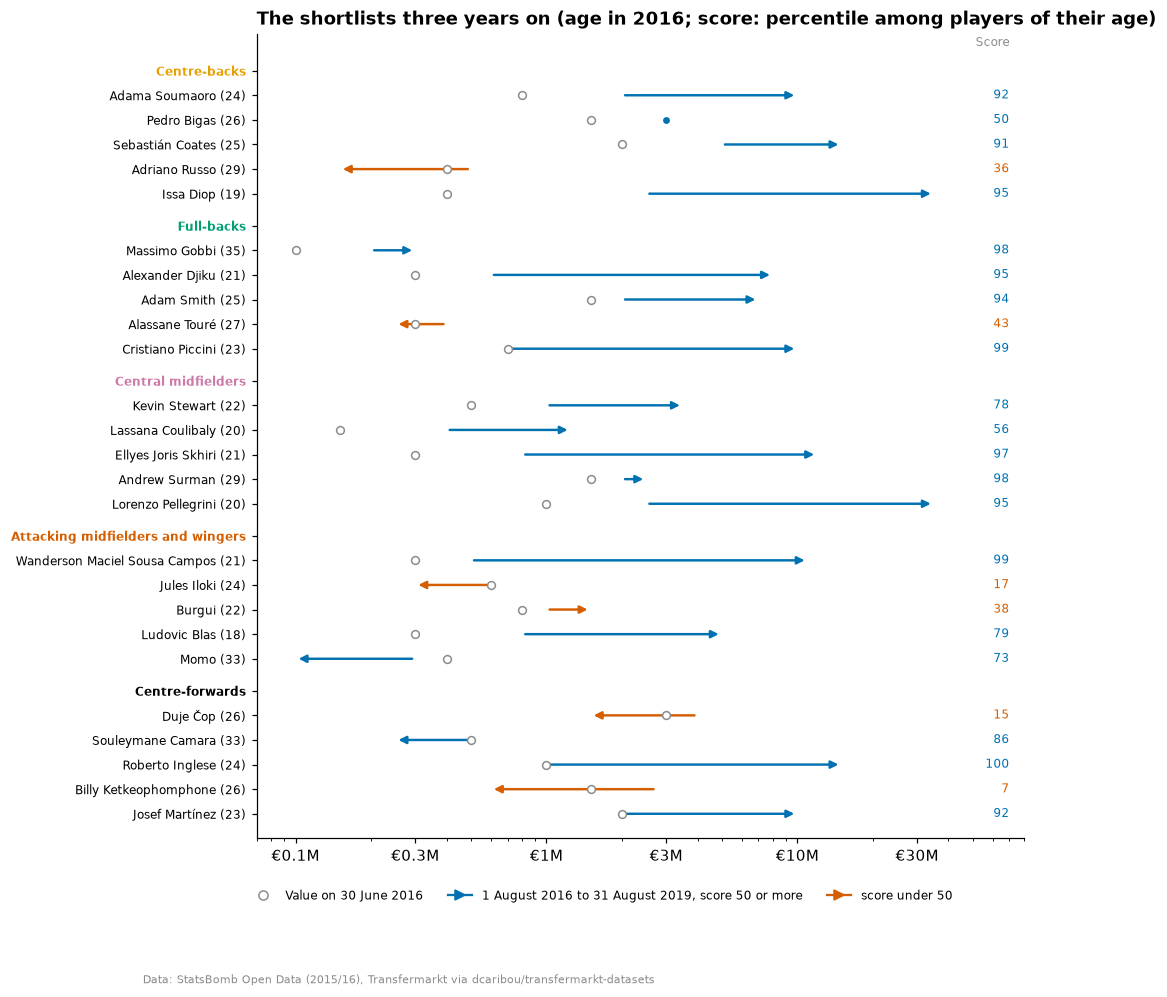

,Players,30 June 2016 (€M),31 August 2019 (€M),Multiple
Gap within team,25,21.9,188.2,×8.6
Gap without the profile,25,21.8,157.7,×7.3
Most minutes,25,79.0,106.5,×1.3
All players within the budget,808,"1,781.3","2,812.1",×1.6


In [27]:
after = outcomes[outcomes.horizon == PRIMARY].set_index("player_id").reindex(shortlist.index)
ABOVE, BELOW = "#0072B2", "#D55E00"
fig, ax = plt.subplots(figsize=(9, 9.5))
y, ticks, labels, headers = 0, [], [], {}
for g in OUTFIELD:
    headers[len(labels)] = GROUP_COLORS[g]
    ticks.append(y)
    labels.append(GROUP_NAMES[g])
    y += 1
    for pid in shortlist.index[shortlist.comparison_group == g]:
        p, score = shortlist.loc[pid], shortlist.loc[pid, SCORE[PRIMARY]]
        color = ABOVE if round(score) >= 50 else BELOW
        ax.annotate(
            "",
            xy=(after.value[pid] / 1e6, y),
            xytext=(after.base[pid] / 1e6, y),
            arrowprops={"arrowstyle": "-|>", "color": color, "lw": 1.6},
        )
        if after.value[pid] == after.base[pid]:
            ax.scatter(after.value[pid] / 1e6, y, color=color, s=12, zorder=3)
        ax.scatter(p.value / 1e6, y, facecolor="white", edgecolor=GREY, s=26, zorder=3)
        ax.text(70, y, f"{score:.0f}", va="center", ha="right", fontsize=8, color=color)
        ticks.append(y)
        labels.append(f"{p.known_as} ({int(p.age)})")
        y += 1
    y += 0.3
ax.set_xscale("log")
ax.set_xlim(0.07, 80)
ax.set_xticks([0.1, 0.3, 1, 3, 10, 30], labels=["€0.1M", "€0.3M", "€1M", "€3M", "€10M", "€30M"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(ticks, labels=labels, fontsize=8)
for i, tick in enumerate(ax.get_yticklabels()):
    if i in headers:
        tick.set(fontweight="bold", color=headers[i])
ax.set_ylim(y - 0.3, -1.5)
ax.grid(axis="y", visible=False)
ax.text(70, -1, "Score", ha="right", fontsize=8, color=GREY)
ax.legend(
    handles=[
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            markerfacecolor="white",
            markeredgecolor=GREY,
            label="Value on 30 June 2016",
        ),
        Line2D(
            [],
            [],
            color=ABOVE,
            marker=">",
            label="1 August 2016 to 31 August 2019, score 50 or more",
        ),
        Line2D([], [], color=BELOW, marker=">", label="score under 50"),
    ],
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.45, -0.05),
    ncol=3,
    frameon=False,
)
ax.set_title(
    "The shortlists three years on (age in 2016; score: percentile among players of their age)"
)
credit(fig)
save(fig, "backtest_shortlists", cfg)
plt.show()

worth = (
    outcomes[outcomes.horizon == PRIMARY].set_index("player_id").value
)  # players no longer valued: their last value
chosen = {name: available.index[short_picks[name]] for name in short_picks} | {
    EVERYONE: available.index
}
money = pd.DataFrame(
    {
        name: {
            "Players": len(rows),
            "30 June 2016 (€M)": data.value[rows].sum() / 1e6,
            "31 August 2019 (€M)": worth[rows].sum() / 1e6,
        }
        for name, rows in chosen.items()
    }
).T
money["Multiple"] = money["31 August 2019 (€M)"] / money["30 June 2016 (€M)"]
display(
    money.style.format("{:,.1f}")
    .format("{:.0f}", subset="Players")
    .format("×{:.1f}", subset="Multiple")
    .set_caption("Total value of each shortlist (players no longer valued at their last value)")
)

**In money, the shortlist's value grew 8.6 times.** The 25 players were valued at €21.9M on 30
June 2016 and at €188.2M three years on; the shortlist of the gap without the profile grew 7.3
times, the most-minutes shortlist 1.3 times and all players within the budget 1.6 times. Two
players carry much of it (Issa Diop and Lorenzo Pellegrini, €35M each), and these are
Transfermarkt's values, not fees. The arrows also show why the score is read against age: Momo and
Souleymane Camara lost value and still score 73 and 86, as most players their age had stopped
being valued.

### 4.3 Hits and misses

What became of each shortlisted player, from the data alone: the clubs named on their values at
the end of each season from 2016/17 to 2018/19 (a club named again the next season shown once),
their level and league minutes in 2018/19 (section 2.3), and whether their 2015/16 team was
relegated, which a club knew by 30 June 2016 (a pool team whose club played no covered first
division in 2016/17).

In [28]:
team_club = (
    con.sql("SELECT team_id, club_id FROM team_map")
    .df()
    .set_index("team_id")
    .club_id.reindex(strength.index)
)
FIRST = cfg.backtest.outcome_base.year  # 2016/17, the first season after the market view
relegated = pd.Series(
    [pd.isna(club_league.get((club, FIRST))) for club in team_club], index=team_club.index
)
named = pd.DataFrame(
    {s: value_at(valuations, f"{s + 1}-06-30").club for s in range(FIRST, PRIMARY.year)}
).reindex(shortlist.index)


def path(clubs):
    """The clubs in order, a club named again in the next season shown once."""
    return " → ".join(c for i, c in enumerate(clubs) if i == 0 or c != clubs.iloc[i - 1])


happened = by_player(
    pd.DataFrame(
        {
            "Age": shortlist.age,
            "Score": shortlist[SCORE[PRIMARY]],
            "Value 1 Aug 2016 (€M)": after.base / 1e6,
            "Value 31 Aug 2019 (€M)": after.value / 1e6,
            "Clubs, 2016/17 to 2018/19": named.apply(path, axis=1),
            "Level in 2018/19": after.level.str.capitalize(),
            "League minutes 2018/19": after.league_minutes,
            "Team relegated in 2016": shortlist.team_id.map(relegated).map(
                {True: "yes", False: ""}
            ),
        }
    ).sort_values("Score", ascending=False)
)
display(
    happened.style.format(
        {
            "Age": lambda v: f"{int(v)}",
            "Score": "{:.0f}",
            "Value 1 Aug 2016 (€M)": "{:.2f}",
            "Value 31 Aug 2019 (€M)": "{:.2f}",
            "League minutes 2018/19": "{:,.0f}",
        }
    ).set_caption("What became of the shortlisted players, by score three years on")
)
team_names = con.sql("SELECT team_id, team_name FROM teams").df().set_index("team_id").team_name
down, within = data.team_id.map(relegated), data.index.isin(available.index)
scored = data[SCORE[PRIMARY]]
print(
    f"Teams relegated at the end of 2015/16: {relegated.sum()} "
    f"({', '.join(sorted(team_names[relegated[relegated].index]))}). Their profiled players score "
    f"{scored[down].mean():.1f} three years on ({down.sum()} players), the others "
    f"{scored[~down].mean():.1f}; within the budget {scored[down & within].mean():.1f} and "
    f"{scored[~down & within].mean():.1f}. Shortlisted players still valued three years on: "
    f"{after.still_valued.sum()} of {len(after)}."
)

Teams relegated at the end of 2015/16: 12 (Aston Villa, Carpi, Frosinone, Gazélec Ajaccio, Getafe, Hellas Verona, Levante UD, Newcastle United, Norwich City, Rayo Vallecano, Stade de Reims, Troyes). Their profiled players score 45.3 three years on (207 players), the others 51.2; within the budget 45.4 and 49.2. Shortlisted players still valued three years on: 25 of 25.


**Most hits moved to bigger clubs or grew where they were; most misses left the covered top
flights.** Thirteen of the 25 scored 90 or more:

- **moved up**: Issa Diop (Toulouse to West Ham United, €2.5M to €35M from 1 August 2016), Lorenzo
  Pellegrini (Sassuolo to Roma, €2.5M to €35M), Cristiano Piccini (Real Betis, Sporting CP,
  Valencia), Alexander Djiku (Bastia to Caen);
- **grew where they were**: Ellyes Skhiri (Montpellier, €0.8M to €12M), Adama Soumaoro (Lille),
  Adam Smith (Bournemouth), Sebastián Coates (Sporting CP), Roberto Inglese (Chievo, then Parma);
- **left the covered leagues and still grew**: Wanderson (from relegated Getafe to Red Bull
  Salzburg and Krasnodar, €0.5M to €11M) and Josef Martínez (Torino to Atlanta United, €2M to
  €10M), a reminder that no league minutes in the covered leagues is not the end of a career
  (section 2.3);
- **kept a value at an age when most lose it**: Massimo Gobbi (35 in 2016) and Andrew Surman (29),
  sound short-term signings rather than resales.

Six scored under 50, four of them attackers. Two followed teams relegated in May 2016: Adriano
Russo stayed with Frosinone, then went to FC Voluntari; Alassane Touré went from Gazélec Ajaccio
to AFC Tubize. Jules Iloki and Billy Ketkeophomphone left the covered top flights (Concordia
Chiajna, Auxerre), and Duje Čop and Burgui stayed in La Liga on its margins (698 and 550 league
minutes in 2018/19). Relegation was known on 30 June 2016 and the shortlist did not use it, but it
is a drag rather than a verdict: the players of the 12 relegated teams score 45.3 three years on
against 51.2 for the others (45.4 and 49.2 within the budget), and Wanderson left relegated Getafe
to score 99.

### What section 4 shows

- **The shortlists**: the five largest gaps within team of each group among players valued at €5M
  or less outside the strongest fifth of teams, 25 players, young (a median 24.5), cheap (a median
  €0.6M) and mostly short of minutes.
- **Three years on they scored 72.9** (90% interval 60.8 to 81.8), 24.6 points above all players
  within the budget, under every budget and length tried and at every horizon. In Transfermarkt
  values the shortlist went from €21.9M to €188.2M (all players within the budget: 1.6 times).
- **The profile still adds nothing detectable**: the gap without it scores the same (72.6). The
  most-minutes shortlist scores 65.6, behind but within the interval.
- **Thirteen hits of 90 or more, six misses under 50**: the hits moved to bigger clubs or grew
  where they were; the misses mostly left the covered top flights, two of them with teams
  relegated in May 2016, which a club knew when it would have bought.
- **Cautions**: 25 players; growth counted from 1 August 2016, after a revaluation that had
  already raised the shortlisted players' values by a median 1.67 times.